[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QSVM_PowerGridAttack_Islam2026.ipynb)

# QSVM / VQC vs classical models for power-system attack detection: Islam 2026 step by step

**Paper.** Md Rezwanul Islam, *Benchmarking Quantum Machine Learning for Power-System Attack Detection: Evaluation Choices Decide the Outcome Before the Models Do*, arXiv:2608.15617 [cs.LG], 16 Aug 2026. DOI/URL: <https://arxiv.org/abs/2608.15617>. Authors' code (QuantumGridBench, MIT): <https://github.com/rzn-git/quantum_grid_attack_detection_benchmark>, pinned here at commit `83cacbd6f7f24f95e78b9d30fabb69c677892d40` (2026-09-15). Data loading rules, split seed, circuit definitions (RY angle map, IQP-style ZZ map with ring entanglement, `AngleEmbedding` + `StronglyEntanglingLayers` VQC), the kernel diagnostics (KTA, geometric difference, relabelling control) and the attack protocol (PGD in units of the train standard deviation of each PCA component) are taken from that commit; the code below is a compact re-implementation that runs on a laptop CPU or a free Colab runtime.

**What this notebook does.** The paper benchmarks fidelity-kernel SVMs (QSVM) and a variational quantum classifier (VQC) against six tuned classical models on the public Mississippi State / Oak Ridge power-system attack dataset, and shows that *evaluation choices* (row-level versus whole-file split, which attacks exist for which model, the surrogate used for transfer attacks, the black-box starting point) decide the conclusions. This notebook downloads the data, rebuilds the 8-qubit pipeline and re-runs the checkable experiments: the split-protocol control (Table I), the matched-dimensionality accuracy comparison (Table II), the kernel diagnostics and positive control (Table VII, Table XI), the bandwidth sweep (Fig. 3), the data-efficiency curve (Fig. 2), white-box / transfer / random-perturbation attacks (Table III, Sec. IV-D to IV-F), the surrogate-fit control (Sec. IV-E), shot noise and label-flip poisoning (Sec. IV-G).

**How to run.** Colab: *Runtime > Change runtime type > CPU*, then *Runtime > Run all*. `FAST_MODE = True` (default) uses reduced budgets and took 34 to 55 minutes on a shared, heavily loaded laptop CPU (single thread; a free Colab CPU runtime should be in the same range); `FAST_MODE = False` uses larger budgets and was not completed for the committed version (estimated well over 90 minutes; see the configuration cell and the table in section 1). A session restart may be needed after the first install cell in Colab. No GPU, no IBM account and no API key are needed.

**What you get at the end.** Class and PCA plots of the real grid data, drawings of the three circuits that are actually simulated, a paper-versus-notebook table with a verdict per claim, and a critical reading of the paper.

## The paper in one page

**Problem.** Machine-learning detectors for power-system cyber-attacks (false data injection, command injection, relay-setting changes) are themselves attack surfaces. QML has been proposed for them with claims of adversarial robustness that come almost only from image data. The paper asks (RQ1) whether hybrid quantum models match tuned classical baselines in accuracy, (RQ2) whether the families differ in robustness and attack transferability, and whether the standard protocol can measure it, (RQ3) how sensitive quantum results are to encoding, qubits, depth, shots and training-set size.

**Decision.** Binary: *attack* (71 %) versus *natural / no event* (29 %). A three-class variant (no event / natural / attack) is used for diagnostics only.

**Data.** Mississippi State / ORNL power-system attack dataset (Pan, Morris, Adhikari): 15 files with 128 columns each (PMU phasors, relay, control-panel and Snort log features), 78,377 rows, 78,368 after removing exact duplicates. Stratified 60/20/20 split with a fixed seed (47,020 training rows). The 15 files are pooled; rows inside a file are near-duplicates.

**Preprocessing.** Median imputation of infinite impedance values, standardisation, PCA to 8 / 12 / 16 components (one qubit per component), rescaling to [-pi, pi]. All fitted on the training split only.

**Models.** Fidelity-kernel SVM `k(x,x') = |<phi(x)|phi(x')>|^2` with an RY angle map or a ZZ feature map (2 repetitions, ring entanglement) and a tuned bandwidth; VQC with RY angle encoding + strongly-entangling layers (depth 2/4/6), Adam, early stopping, class-weighted loss; six tuned classical models (logistic regression, RBF-SVM, random forest, XGBoost, LightGBM, 2-layer MLP). Kernel training is capped at 2,000 stratified samples and every classical model in the PCA regime is capped identically.

**Attacks.** L-infinity PGD (20 steps, step 0.25 eps, one random start) with eps in units of the per-component train standard deviation; white-box on MLP, VQC and both kernel machines, transfer from an MLP surrogate for the rest, a random-perturbation control, HopSkipJump (not reproduced here), label-flip poisoning, Gaussian sensor noise.

**Headline claims (what this notebook tests).** (1) row-level split scores 0.905 macro-F1 with full-feature LightGBM, whole-file held-out leaves 0.594; (2) at PCA-8 with 2,000 samples classical XGBoost (0.597) beats the ZZ-QSVM (0.564) and the VQC (0.514) by a few points, and on whole-file splits both sit near chance (0.523 / 0.508 versus floor 0.499); (3) quantum-kernel target alignment stays below 0.015 although the geometric difference is large, and a positive control shows the pipeline can detect a quantum win when labels are built for it; (4) the transferred PGD attack leaves the QSVM at 88.6 % of clean macro-F1, but a differentiated white-box attack drives it to 6.4 %, against 68.5 % for the RBF-SVM; (5) the apparent MLP-to-VQC transfer asymmetry (10.2x) collapses to 0.8x when the MLP surrogate is refitted with balanced sample weights; (6) random noise flips 45 % of the QSVM's predictions at 0.5 sigma.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MSU/ORNL power-system attack, binary variant, retrieved from the maintainer's UAH page on 2026-08-13 | Same files, SHA-256 checked against the hashes recorded in the authors' `configs/data.yaml`. The UAH link now returns HTTP 404, so the notebook falls back to the Internet Archive copy of the same file (identical hash). Three-class variant for the Appendix D check. |
| Rows / split | 78,368 rows, 60/20/20 stratified, 47,020 train | Same (split seed 1337 from the authors' config) |
| Hyper-parameter search | Optuna, 50 trials per model, 3 tuning seeds | Seeded random search with `TUNE_TRIALS` trials (6 fast / 12 full) for logistic regression, random forest, XGBoost, boosting and MLP; a (gamma, C) grid for the RBF-SVM; a log-spaced bandwidth grid x a C grid for the QSVM; one tuning seed, objective = validation macro-F1 (`# CHOICE:`) |
| LightGBM | tuned LightGBM | scikit-learn `HistGradientBoostingClassifier` (same histogram-GBDT family, `class_weight="balanced"`) so that no extra package is needed (`# CHOICE:`). Called `hgb` below. In fast mode it is one large fixed configuration (no search), in full mode a 3-trial search. |
| Seeds | 10 | `N_SEEDS` model seeds (3 fast / 10 full). Fixed 2,000-row stratified training subset (as in the paper). |
| Kernel simulator | PennyLane statevectors | PennyLane `default.qubit` with parameter broadcasting; same gate list as the authors' `qkernel.py`. Gram matrix from stored statevectors (exact identity), checked against the compute-uncompute circuit. |
| VQC | PennyLane + PyTorch, Adam, early stopping | PennyLane + autograd (no PyTorch), manual Adam, class-weighted BCE, early stopping on validation macro-F1; depth/learning-rate grid instead of Optuna (`# CHOICE:`). 8 qubits only (the paper also ran 12). |
| White-box QSVM attack | torch graph through the simulator | autograd graph through the same simulator, with a numeric gate (forward vs sklearn, gradient vs finite differences) |
| Attack points / seeds | 500 stratified test points, 10 attack seeds | `N_ATTACK` points (200 fast / 300 full), `N_ATTACK_SEEDS` = 2 seeds |
| HopSkipJump (ART) | 100 points x 5 restarts | **Not run**: needs the Adversarial Robustness Toolbox and hours of CPU. Claim reported as "cannot be checked". |
| Depolarizing-noise ablation | density-matrix kernels | **Not run**: 4^8 amplitudes per sample is too large for a shared machine. Shot noise is run. |
| Test set for kernels | full test split | `TEST_N` stratified test rows in fast mode (4,000), the full test split (15,674) in full mode; all models see the same rows |
| Whole-file partitions | 5 partitions | `N_PARTITIONS` (2 fast / 3 full), drawn from `np.random.default_rng(0)` like the authors' `run_group_split_control.py` |

In [1]:
# Install (pinned to the versions tested for this notebook). Colab already ships numpy, pandas, scikit-learn,
# scipy, matplotlib and xgboost. The guard avoids re-installing on a machine that already has the packages.
import os, sys, subprocess, importlib
# Thread control (must happen before numpy / scikit-learn are imported). Colab has 2 vCPUs; on a busy shared machine
# set QC054_THREADS=1, because OpenMP spin-waiting on an oversubscribed CPU makes boosting 50x slower.
N_JOBS = int(os.environ.get("QC054_THREADS", "2"))
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_JOBS))
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("pennylane", "py7zr", "xgboost", "sklearn", "scipy", "requests"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "pennylane==0.45.1", "py7zr", "xgboost", "requests"])
    print("Installed. If Colab complains about numpy, use Runtime > Restart session and run again.")
else:
    print("All packages already available; skipping install.")

All packages already available; skipping install.


## 1. Configuration

Every tunable constant is here. `FAST_MODE=True` is the class-demo path; `FAST_MODE=False` is the larger path (more tuning trials, 10 model seeds, the full test split, three whole-file partitions, 300 attack points, VQC depth search over {2, 4}). Neither reaches the paper's 50-trial Optuna budget with 10 seeds and 10 attack seeds, which took the authors about a day on 24 cores.

In [2]:
import os
from pathlib import Path

FAST_MODE = True                  # True: reduced budgets (~30 min on a laptop CPU). False: larger budgets.
SEED = 42                         # global seed
SPLIT_SEED = 1337                 # train/val/test split seed from the authors' configs/data.yaml
N_QUBITS = 8                      # PCA dimension = number of qubits (paper: 8, 12, 16; 8 here)
KERNEL_CAP = 2000                 # stratified training cap for kernel and matched-dimensionality models (paper: 2,000)
DATA_DIR = Path(os.environ.get("QC054_DATA_DIR", "qc054_data"))   # downloaded archives are cached here
IBM_TOKEN = ""                    # unused: everything is simulated

# --- budgets that depend on FAST_MODE (the full path is trimmed to about 1.5 to 2 hours on a shared CPU; the paper used 50 Optuna trials, 10 seeds, 500 attack points x 10 seeds, 5 partitions, about a day on 24 cores) ---
TUNE_TRIALS   = 6    if FAST_MODE else 12      # random-search trials per model (paper: 50 Optuna trials)
TUNE_VAL      = 1000 if FAST_MODE else 2000    # stratified validation rows used while tuning
N_SEEDS       = 3    if FAST_MODE else 10      # model seeds for the final cheap models (paper: 10)
TEST_N        = 4000 if FAST_MODE else None    # stratified test rows for kernel work (None = full test split)
N_PARTITIONS  = 2    if FAST_MODE else 3       # whole-file hold-out partitions (paper: 5)
N_NEIGHBOUR_Q = 2000 if FAST_MODE else 3000    # test rows used by the near-duplicate audit
N_ATTACK      = 200  if FAST_MODE else 300     # stratified test points attacked (paper: 500)
N_ATTACK_SEEDS = 2   if FAST_MODE else 2       # attack seeds (paper: 10)
ATTACK_EPS    = [0.01, 0.1, 0.5] if FAST_MODE else [0.01, 0.1, 0.3, 0.5]   # in units of train sigma
HEADLINE_EPS  = 0.5
VQC_DEPTHS    = [2] if FAST_MODE else [2, 4]
VQC_LRS       = [0.05] if FAST_MODE else [0.02, 0.05, 0.1]
VQC_EPOCHS    = 10   if FAST_MODE else 12
VQC_PATIENCE  = 4
VQC_BATCH     = 64
BW_SWEEP      = [0.1, 0.4, 0.8, 1.6, 3.0] if FAST_MODE else [0.1, 0.2, 0.4, 0.8, 1.6, 2.0, 3.0]
SWEEP_N       = 1000 if FAST_MODE else 2000   # train/val rows in the bandwidth sweep
RELABEL_RESAMPLES = 3 if FAST_MODE else 5
DATA_SIZES    = [250, 500, 1000, 2000]        # data-efficiency curve
POISON_RATES  = [0.05, 0.10, 0.20]
SHOTS         = [1024, 4096]
print(f"FAST_MODE={FAST_MODE}  TUNE_TRIALS={TUNE_TRIALS}  N_SEEDS={N_SEEDS}  TEST_N={TEST_N}  N_ATTACK={N_ATTACK}")

FAST_MODE=True  TUNE_TRIALS=6  N_SEEDS=3  TEST_N=4000  N_ATTACK=200


In [3]:
import time, json, math, random, hashlib, warnings, glob
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import xgboost
import pennylane as qml
import pennylane.numpy as pnp
import requests
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, balanced_accuracy_score, average_precision_score, roc_auc_score,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
T0 = time.time()

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| scipy", scipy.__version__, "| xgboost", xgboost.__version__, "| pennylane", qml.__version__)

# Hugging Face token handling (required by the repository's rules; this dataset is NOT on Hugging Face and is not gated,
# so the token is never used here. If you point DATA_URLS at a gated mirror, put your own token into Colab Secrets
# as HF_TOKEN; never paste it into the notebook).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | xgboost 3.4.1 | pennylane 0.45.1


## 2. Data: download, verify, pool, clean, split

The dataset is distributed as `.7z` archives of 15 CSV files each. The authors recorded the SHA-256 of each archive on 2026-08-13 in `configs/data.yaml`; the notebook refuses any file whose hash differs. The original UAH address now returns 404, so the second address is the Internet Archive snapshot of the same file (verified to have the identical hash). If you already have the archives, drop them into `DATA_DIR`.

Pipeline (identical to `qgridbench/data/preprocess.py`): pool the 15 files in sorted file-name order, map `Natural -> 0`, `Attack -> 1`, turn `+-inf` into `NaN` (imputed later from the training split), drop exact duplicate rows *before* splitting, then a stratified 60/20/20 split with seed 1337. We also keep the source-file id of every row because the paper's central control holds whole files out.

In [4]:
ARCHIVES = {
    "binary": dict(
        file="binaryAllNaturalPlusNormalVsAttacks.7z",
        sha256="b02c16bd74374d782298767708453570e4bc85e6a6e176c56a9c552358d472f8",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z",
              "http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z"],
        labels={"Natural": 0, "Attack": 1}),
    "triple": dict(
        file="triple.7z",
        sha256="8bcf90a7b656cd3c73dd809a8b8b657444c5512731811875d2dbc6b44448331c",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/triple.7z",
              "http://web.archive.org/web/20251204094307id_/http://www.ece.uah.edu/~thm0009/icsdatasets/triple.7z"],
        labels={"NoEvents": 0, "Natural": 1, "Attack": 2}),
}

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def ensure_archive(variant):
    spec = ARCHIVES[variant]
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    dest = DATA_DIR / spec["file"]
    if dest.exists() and sha256_file(dest) == spec["sha256"]:
        return dest
    last = None
    for url in spec["urls"]:
        try:
            print("downloading", url)
            with requests.get(url, stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            if sha256_file(dest) == spec["sha256"]:
                return dest
            last = "SHA-256 mismatch"
        except Exception as e:
            last = repr(e)
    raise RuntimeError(f"could not obtain {spec['file']} with a matching SHA-256 ({last}). "
                       f"Download it manually and place it in {DATA_DIR.resolve()}.")

def load_pooled(variant):
    import py7zr
    arch = ensure_archive(variant)
    out = DATA_DIR / variant
    if not list(out.rglob("*.csv")):
        out.mkdir(exist_ok=True)
        with py7zr.SevenZipFile(arch) as z:
            z.extractall(out)
    files = sorted(out.rglob("*.csv"))             # sorted file-name order, as in the authors' code
    frames = []
    for f in files:
        df = pd.read_csv(f)
        df.columns = [c.strip() for c in df.columns]
        frames.append(df)
    gid = np.concatenate([np.full(len(f), i, dtype=np.int16) for i, f in enumerate(frames)])
    pooled = pd.concat(frames, ignore_index=True)
    return pooled, gid, [f.name for f in files]

def build_table(variant, split_seed=SPLIT_SEED):
    spec = ARCHIVES[variant]
    pooled, gid, fnames = load_pooled(variant)
    unknown = set(pooled["marker"].unique()) - set(spec["labels"])
    assert not unknown, f"unmapped labels {unknown}"
    y = pooled["marker"].map(spec["labels"]).to_numpy(np.int64)
    feat_names = [c for c in pooled.columns if c != "marker"]
    X = pooled[feat_names].to_numpy(np.float64)
    n_inf = int(np.isinf(X).sum())
    X[np.isinf(X)] = np.nan                         # infinite impedances -> NaN; imputed from the TRAIN split later
    raw_counts = pooled["marker"].value_counts().to_dict()
    df = pd.DataFrame(X); df["__y"] = y
    keep = (~df.duplicated()).to_numpy()            # exact duplicates removed BEFORE the split
    del df
    X, y, gid = X[keep], y[keep], gid[keep]
    idx = np.arange(len(y))
    tr, tmp = train_test_split(idx, train_size=0.6, stratify=y, random_state=split_seed)
    va, te = train_test_split(tmp, train_size=0.5, stratify=y[tmp], random_state=split_seed)
    return dict(X=X, y=y, gid=gid, feat=feat_names, files=fnames, raw_rows=len(pooled), n_inf=n_inf,
                raw_counts=raw_counts, label_names={v: k for k, v in spec["labels"].items()},
                split=dict(train=np.sort(tr), val=np.sort(va), test=np.sort(te)))

TAB = {}
for v in ("binary", "triple"):
    TAB[v] = build_table(v)
    t = TAB[v]
    print(f"{v}: raw rows {t['raw_rows']:,} -> {len(t['y']):,} after dedup | inf cells -> NaN: {t['n_inf']:,} | "
          f"train/val/test = {len(t['split']['train']):,}/{len(t['split']['val']):,}/{len(t['split']['test']):,}")
b = TAB["binary"]
assert len(b["y"]) == 78368 and len(b["split"]["train"]) == 47020, "does not match the paper's row counts"
print("binary class share (attack):", round(float(b["y"].mean()), 3), "| paper: 71 % attack / 29 % natural")
print("OK: 78,368 rows and 47,020 training rows, as stated in the paper.")

binary: raw rows 78,377 -> 78,368 after dedup | inf cells -> NaN: 10,906 | train/val/test = 47,020/15,674/15,674


triple: raw rows 78,377 -> 78,368 after dedup | inf cells -> NaN: 10,906 | train/val/test = 47,020/15,674/15,674
binary class share (attack): 0.71 | paper: 71 % attack / 29 % natural
OK: 78,368 rows and 47,020 training rows, as stated in the paper.


## 3. Dataset Exploration and Visualisation

Everything below uses the real measurements and their ground-truth labels. The binary task has two labels (*Natural*, *Attack*). The three-class release keeps the third label *NoEvents* (normal operation), so we show it too: colouring by the three classes keeps the structure that the binary label hides. The feature-space plots follow the model pipeline: median imputation, standardisation and PCA fitted on the **training split only**, then the same coordinates scaled to [-pi, pi] (the rotation angles of the circuits).

BINARY  X shape (rows, features): (78368, 128) | y shape: (78368,)
number of source files: 15 -> ['data1.csv', 'data10.csv', 'data11.csv', 'data12.csv', 'data13.csv', 'data14.csv', 'data15.csv', 'data2.csv', 'data3.csv', 'data4.csv', 'data5.csv', 'data6.csv', 'data7.csv', 'data8.csv', 'data9.csv']
128 feature names. First 12: ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I']
last 12: ['control_panel_log1', 'control_panel_log2', 'control_panel_log3', 'control_panel_log4', 'relay1_log', 'relay2_log', 'relay3_log', 'relay4_log', 'snort_log1', 'snort_log2', 'snort_log3', 'snort_log4']
feature groups (prefix -> #columns): {'R1': 29, 'R2': 29, 'R3': 29, 'R4': 29, 'control_panel': 4, 'other': 4, 'snort': 4}
original labels (raw, before dedup): {'Attack': 55663, 'Natural': 22714}
after dedup: {'Natural': 22706, 'Attack': 55662}

THREE-CLASS  X shape: (78368, 128) | original labels (raw): {'Atta

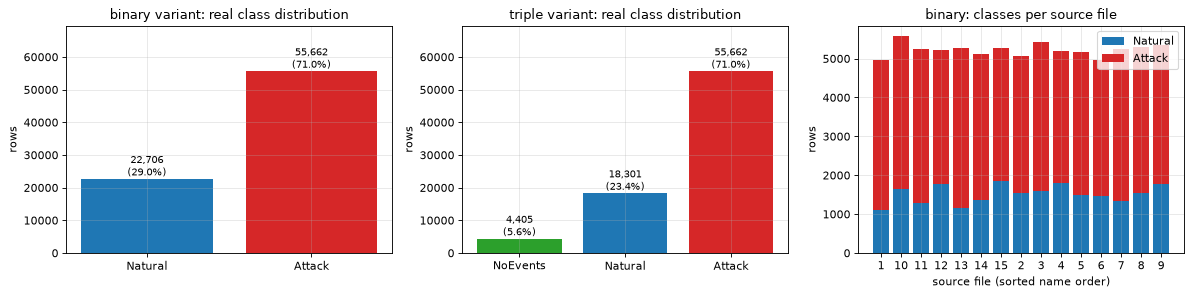

In [5]:
b = TAB["binary"]; t3 = TAB["triple"]
print("BINARY  X shape (rows, features):", b["X"].shape, "| y shape:", b["y"].shape)
print("number of source files:", len(b["files"]), "->", b["files"])
print(f"{len(b['feat'])} feature names. First 12:", b["feat"][:12])
print("last 12:", b["feat"][-12:])
groups = pd.Series(b["feat"]).str.extract(r"^(R\d+|control_panel|snort)", expand=False).fillna("other").value_counts()
print("feature groups (prefix -> #columns):", groups.to_dict())
print("original labels (raw, before dedup):", b["raw_counts"])
print("after dedup:", {b["label_names"][k]: int(v) for k, v in zip(*np.unique(b["y"], return_counts=True))})
print("\nTHREE-CLASS  X shape:", t3["X"].shape, "| original labels (raw):", t3["raw_counts"])
print("after dedup:", {t3["label_names"][k]: int(v) for k, v in zip(*np.unique(t3["y"], return_counts=True))})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (name, tab) in zip(ax[:2], TAB.items()):
    vals, cnt = np.unique(tab["y"], return_counts=True)
    names = [tab["label_names"][v] for v in vals]
    cols = {"Natural": "tab:blue", "Attack": "tab:red", "NoEvents": "tab:green"}
    bars = a.bar(names, cnt, color=[cols[n] for n in names])
    for bar_, c_ in zip(bars, cnt):
        a.text(bar_.get_x() + bar_.get_width() / 2, c_, f"{c_:,}\n({c_ / cnt.sum():.1%})", ha="center", va="bottom", fontsize=9)
    a.set_title(f"{name} variant: real class distribution"); a.set_ylabel("rows"); a.set_ylim(0, cnt.max() * 1.25)
files_ = np.arange(len(b["files"]))
nat = np.array([((b["gid"] == i) & (b["y"] == 0)).sum() for i in files_])
att = np.array([((b["gid"] == i) & (b["y"] == 1)).sum() for i in files_])
ax[2].bar(files_, nat, label="Natural", color="tab:blue"); ax[2].bar(files_, att, bottom=nat, label="Attack", color="tab:red")
ax[2].set_xticks(files_); ax[2].set_xticklabels([f.replace("data", "").replace(".csv", "") for f in b["files"]])
ax[2].set_xlabel("source file (sorted name order)"); ax[2].set_ylabel("rows"); ax[2].set_title("binary: classes per source file"); ax[2].legend()
plt.tight_layout(); plt.show()

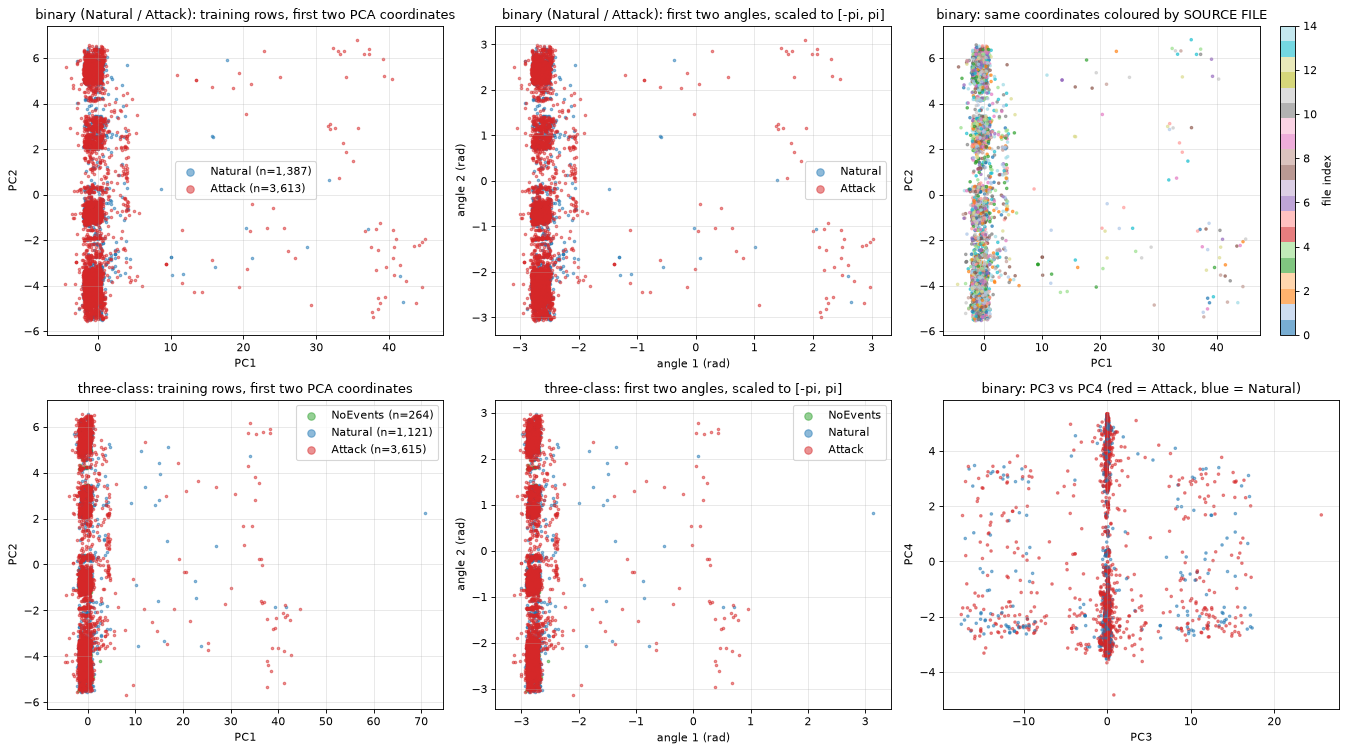

binary PCA-8 explained variance ratio: [0.149 0.117 0.088 0.07  0.061 0.046 0.038 0.034] | total 0.602
Reading: classes overlap heavily in the first two components, and rows from the same file cluster together; both are consistent with the paper's finding that a row-level split mostly rewards memorising file-specific clusters.


In [6]:
class Prep:
    # median-impute -> standardise -> PCA(n) -> MinMax to [-pi, pi]; every transform is fitted on the training rows only.
    def __init__(self, X_train, n_components=None, seed=SEED):
        self.imp = SimpleImputer(strategy="median").fit(X_train)
        self.sc = StandardScaler().fit(self.imp.transform(X_train))
        Zs = self.sc.transform(self.imp.transform(X_train))
        self.pca = PCA(n_components=n_components, random_state=seed).fit(Zs) if n_components else None
        Z = self.pca.transform(Zs) if self.pca else Zs
        self.mm = MinMaxScaler((-np.pi, np.pi)).fit(Z)
        self.sigma = Z.std(axis=0, ddof=0)          # per-component train std = unit of the attack budget
    def std(self, X):                                # standardised full-feature space
        return self.sc.transform(self.imp.transform(X))
    def pca_space(self, X):                          # PCA coordinates (the models' input space for classical models)
        Zs = self.std(X)
        return self.pca.transform(Zs) if self.pca else Zs
    def angles(self, Z):                             # rotation angles; test values outside the train range are clipped
        return np.clip(self.mm.transform(Z), -np.pi, np.pi)

def scatter_pca(tab, title, n_plot=5000, seed=SEED, colour_by="label"):
    tr = tab["split"]["train"]
    P = Prep(tab["X"][tr], N_QUBITS)
    rng = np.random.default_rng(seed)
    sel = rng.choice(len(tr), size=min(n_plot, len(tr)), replace=False)
    Z = P.pca_space(tab["X"][tr[sel]]); A = P.angles(Z); yy = tab["y"][tr[sel]]
    return P, Z, A, yy, tr[sel]

fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
palette3 = {0: ("NoEvents", "tab:green"), 1: ("Natural", "tab:blue"), 2: ("Attack", "tab:red")}
palette2 = {0: ("Natural", "tab:blue"), 1: ("Attack", "tab:red")}
Pb, Zb, Ab, yb_, selb = scatter_pca(TAB["binary"], "binary")
Pt, Zt, At, yt_, selt = scatter_pca(TAB["triple"], "triple")
for row, (Zp, yy, pal, ttl) in enumerate([(Zb, yb_, palette2, "binary (Natural / Attack)"), (Zt, yt_, palette3, "three-class")]):
    for k, (nm, c) in pal.items():
        m = yy == k
        ax[row, 0].scatter(Zp[m, 0], Zp[m, 1], s=5, alpha=0.5, c=c, label=f"{nm} (n={m.sum():,})")
    ax[row, 0].set_title(f"{ttl}: training rows, first two PCA coordinates"); ax[row, 0].set_xlabel("PC1"); ax[row, 0].set_ylabel("PC2"); ax[row, 0].legend(markerscale=3)
    Ap = Pb.angles(Zp) if row == 0 else Pt.angles(Zp)
    for k, (nm, c) in pal.items():
        m = yy == k
        ax[row, 1].scatter(Ap[m, 0], Ap[m, 1], s=5, alpha=0.5, c=c, label=nm)
    ax[row, 1].set_title(f"{ttl}: first two angles, scaled to [-pi, pi]"); ax[row, 1].set_xlabel("angle 1 (rad)"); ax[row, 1].set_ylabel("angle 2 (rad)"); ax[row, 1].legend(markerscale=3)
gid_sel = TAB["binary"]["gid"][selb]
sc_ = ax[0, 2].scatter(Zb[:, 0], Zb[:, 1], s=5, alpha=0.6, c=gid_sel, cmap="tab20")
ax[0, 2].set_title("binary: same coordinates coloured by SOURCE FILE"); ax[0, 2].set_xlabel("PC1"); ax[0, 2].set_ylabel("PC2")
plt.colorbar(sc_, ax=ax[0, 2], label="file index")
ax[1, 2].scatter(Zb[:, 2], Zb[:, 3], s=5, alpha=0.5, c=[palette2[int(k)][1] for k in yb_])
ax[1, 2].set_title("binary: PC3 vs PC4 (red = Attack, blue = Natural)"); ax[1, 2].set_xlabel("PC3"); ax[1, 2].set_ylabel("PC4")
plt.tight_layout(); plt.show()
ev = Pb.pca.explained_variance_ratio_
print("binary PCA-8 explained variance ratio:", np.round(ev, 3), "| total", round(float(ev.sum()), 3))
print("Reading: classes overlap heavily in the first two components, and rows from the same file cluster together; "
      "both are consistent with the paper's finding that a row-level split mostly rewards memorising file-specific clusters.")

## 4. Preprocessing for the matched-dimensionality regime

The paper compares quantum and classical models in a regime where both see the same 8 PCA components and the same 2,000 stratified training rows (the Gram matrix of a fidelity kernel costs O(N^2) circuit evaluations, so the cap is forced by the quantum model and applied to every classical model too). Every fitted transform below sees the training split only; validation rows are used only to tune, test rows only to score. Classical models consume the PCA coordinates `Z`; the quantum models consume `Z` after the train-fitted MinMax map to [-pi, pi] (their rotation angles, clipped for out-of-range test rows).

In [7]:
b = TAB["binary"]
Xb, yb, gidb = b["X"], b["y"], b["gid"]
S = b["split"]
def strat_idx(y, n, seed):
    # deterministic stratified subset (sorted indices) of size <= n
    if n is None or len(y) <= n:
        return np.arange(len(y))
    keep, _ = train_test_split(np.arange(len(y)), train_size=n, stratify=y, random_state=seed)
    return np.sort(keep)

P8 = Prep(Xb[S["train"]], N_QUBITS)                      # fitted on the 47,020 training rows only
Ztr_all = P8.pca_space(Xb[S["train"]]); ytr_all = yb[S["train"]]
cap = strat_idx(ytr_all, KERNEL_CAP, 0)                  # fixed 2,000-row stratified training subset
Z_tr, y_tr = Ztr_all[cap], ytr_all[cap]
va_sub = strat_idx(yb[S["val"]], TUNE_VAL, 1)
Z_va, y_va = P8.pca_space(Xb[S["val"]][va_sub]), yb[S["val"]][va_sub]
te_sub = strat_idx(yb[S["test"]], TEST_N, 2)
Z_te, y_te = P8.pca_space(Xb[S["test"]][te_sub]), yb[S["test"]][te_sub]
SIGMA = Ztr_all.std(axis=0, ddof=0)                      # attack unit (train std per PCA component)
print(f"train subset {Z_tr.shape} (attack share {y_tr.mean():.3f}) | tuning-val {Z_va.shape} | test {Z_te.shape} (attack share {y_te.mean():.3f})")
print("PCA component std on the training split (the epsilon unit):", np.round(SIGMA, 2))
print("angle range of the training subset:", np.round(P8.angles(Z_tr).min(), 2), "to", np.round(P8.angles(Z_tr).max(), 2))

train subset (2000, 8) (attack share 0.711) | tuning-val (1000, 8) | test (4000, 8) (attack share 0.710)
PCA component std on the training split (the epsilon unit): [4.37 3.87 3.36 2.99 2.79 2.43 2.21 2.07]
angle range of the training subset: -3.12 to 3.14


## 5. Quantum Circuit Architecture

Three gate-based models are simulated, all on 8 qubits (one per PCA component) with exact statevectors on PennyLane's `default.qubit` (parameter broadcasting evaluates a whole batch in one call):

1. **RY angle-map fidelity kernel** (`angle_ry`): one `RY(c*x_i)` per qubit, no entanglement. The kernel is `|<phi(x)|phi(x')>|^2`; `c` is the tuned *bandwidth*.
2. **ZZ-map fidelity kernel** (`zz`): two repetitions of [H, `RZ(2 c x_i)` on every qubit; ring of `CNOT - RZ(2 c^2 x_i x_j) - CNOT`]. This is the IQP-style map of the authors' `qkernel.py` (Fig. 1 of the paper shows a 3-qubit sketch). **Assumption (paper text silent):** the bandwidth multiplies the angle once, so the pair term carries `c^2`; the "ring" closes between qubit 7 and qubit 0.
3. **VQC**: `AngleEmbedding(rotation="Y")` followed by `StronglyEntanglingLayers(depth)` and a `PauliZ` expectation on qubit 0, turned into a probability by a trainable scale/bias and a sigmoid. **Assumption:** measurement on qubit 0 only (binary task), as in the authors' multiclass strategy.

The kernels are evaluated as statevector overlaps (`|<psi_i|psi_j>|^2`, an exact identity for pure states). On hardware the same number is the probability of the all-zero outcome of the *compute-uncompute* circuit `U(x')^dagger U(x)`; the last cells of this section draw that circuit and assert numerically that it reproduces the statevector overlap, so the Gram matrices used below are what a device would estimate (without shot noise, which section 14 adds). Below we draw the QNode objects that are executed, with a real training row as input.

In [8]:
n = N_QUBITS
dev_sv = qml.device("default.qubit", wires=n)

def fmap(x, enc):
    # gate list of the feature map; x[..., i] allows a batch of rows (parameter broadcasting)
    if enc == "angle_ry":
        for i in range(n):
            qml.RY(x[..., i], wires=i)
    elif enc == "zz":
        for _ in range(2):                                    # 2 repetitions
            for i in range(n):
                qml.Hadamard(wires=i)
                qml.RZ(2.0 * x[..., i], wires=i)
            for i in range(n):                                # ring entanglement
                j = (i + 1) % n
                qml.CNOT(wires=[i, j])
                qml.RZ(2.0 * x[..., i] * x[..., j], wires=j)
                qml.CNOT(wires=[i, j])
    else:
        raise ValueError(enc)

def make_state_qnode(enc):
    def circ(x):
        fmap(x, enc)
        return qml.state()
    return qml.QNode(circ, dev_sv, interface="autograd", diff_method="backprop")

STATE_QN = {e: make_state_qnode(e) for e in ("angle_ry", "zz")}

def compute_states(A, enc, bw=1.0, chunk=512):
    # statevectors of the feature map for every row of A (angles); bandwidth c multiplies the angles
    out = np.empty((len(A), 2 ** n), dtype=np.complex128)
    for s in range(0, len(A), chunk):
        out[s:s + chunk] = np.asarray(STATE_QN[enc](bw * np.asarray(A[s:s + chunk], dtype=np.float64)))
    return out

def gram(Sa, Sb):
    return np.clip(np.abs(Sa.conj() @ Sb.T) ** 2, 0.0, 1.0)

@qml.qnode(dev_sv)
def overlap_circuit_zz(x1, x2):
    fmap(x1, "zz"); qml.adjoint(fmap)(x2, "zz")
    return qml.probs(wires=range(n))

@qml.qnode(dev_sv)
def overlap_circuit_ry(x1, x2):
    fmap(x1, "angle_ry"); qml.adjoint(fmap)(x2, "angle_ry")
    return qml.probs(wires=range(n))

@qml.qnode(qml.device("default.qubit", wires=n), interface="autograd", diff_method="backprop")
def vqc_qnode(x, w):
    qml.AngleEmbedding(x, wires=range(n), rotation="Y")
    qml.StronglyEntanglingLayers(w, wires=range(n))
    return qml.expval(qml.PauliZ(0))

def circuit_stats(qn, *args):
    try:
        sp = qml.specs(qn, level="device")(*args)
        return int(sp.resources.depth), int(sp.resources.num_gates), int(sp.num_device_wires)
    except Exception as e:
        tape = qml.workflow.construct_batch(qn, level="device")(*args)[0][0]
        return int(tape.graph.get_depth()), len(tape.operations), len(tape.wires)

A_demo = P8.angles(Z_tr)[:1][0]
print("demo input = angles of the first real training row:", np.round(A_demo, 2))

demo input = angles of the first real training row: [-2.28 -0.1  -0.41  3.11  2.69  0.28  1.91  2.01]


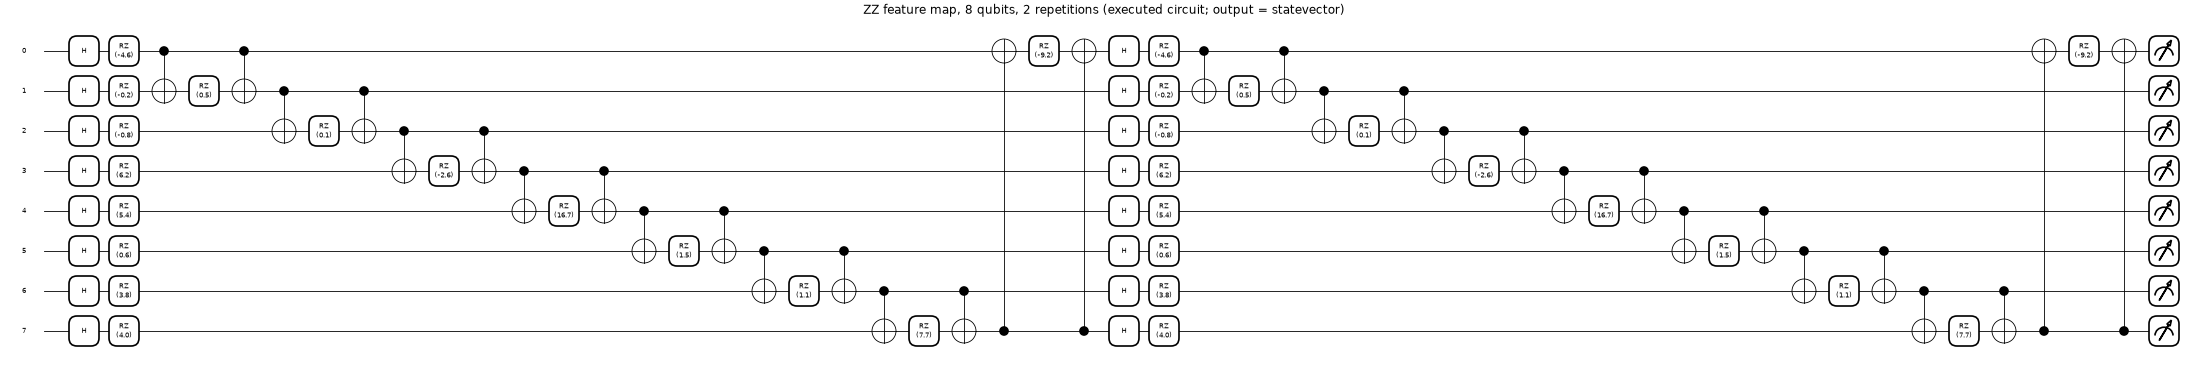

ZZ kernel circuit: qubits=8, depth=52, gates=80, trainable parameters=0 (data-dependent angles; 1 tuned bandwidth hyper-parameter)


In [9]:
# --- ZZ-map kernel circuit (the QNode that compute_states() executes) ---
bw_demo = 1.0
fig, ax = qml.draw_mpl(STATE_QN["zz"], decimals=1, fontsize=13)(bw_demo * A_demo)
fig.set_dpi(40); fig.suptitle("ZZ feature map, 8 qubits, 2 repetitions (executed circuit; output = statevector)", fontsize=22, y=1.02)
plt.show()
d, g_, q_ = circuit_stats(STATE_QN["zz"], bw_demo * A_demo)
print(f"ZZ kernel circuit: qubits={q_}, depth={d}, gates={g_}, trainable parameters=0 (data-dependent angles; 1 tuned bandwidth hyper-parameter)")

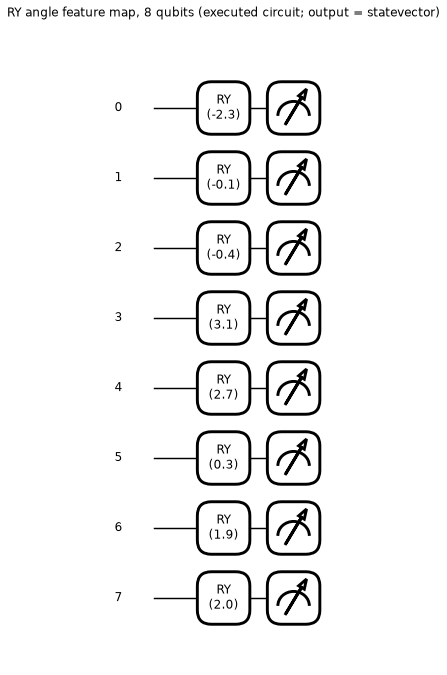

RY kernel circuit: qubits=8, depth=1, gates=8, trainable parameters=0 (1 tuned bandwidth hyper-parameter)


In [10]:
# --- RY angle-map kernel circuit ---
fig, ax = qml.draw_mpl(STATE_QN["angle_ry"], decimals=1, fontsize=12)(bw_demo * A_demo)
fig.set_dpi(70); fig.suptitle("RY angle feature map, 8 qubits (executed circuit; output = statevector)", y=1.05)
plt.show()
d, g_, q_ = circuit_stats(STATE_QN["angle_ry"], bw_demo * A_demo)
print(f"RY kernel circuit: qubits={q_}, depth={d}, gates={g_}, trainable parameters=0 (1 tuned bandwidth hyper-parameter)")

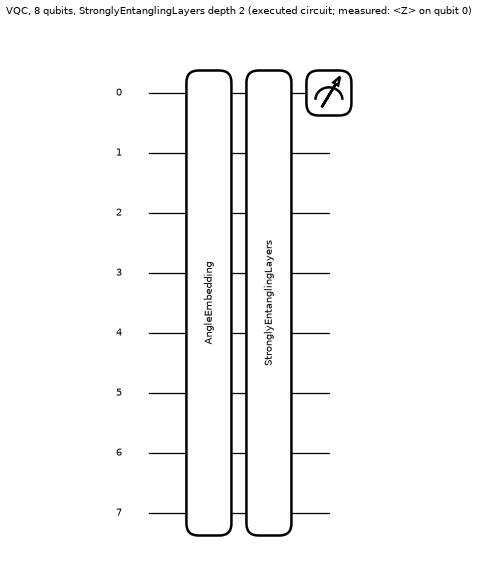

VQC depth 2: qubits=8, depth=15, gates=40, trainable circuit parameters=48 (= 2 layers x 8 qubits x 3) + 2 classical head parameters (scale, bias)


In [11]:
# --- VQC: one drawing per candidate depth (the depth actually used is chosen by validation in section 8) ---
for depth in VQC_DEPTHS:
    w_demo = pnp.array(0.1 * np.random.default_rng(0).standard_normal(qml.StronglyEntanglingLayers.shape(depth, n)), requires_grad=True)
    fig, ax = qml.draw_mpl(vqc_qnode, decimals=1, fontsize=12)(A_demo, w_demo)
    fig.set_dpi(60); fig.suptitle(f"VQC, 8 qubits, StronglyEntanglingLayers depth {depth} (executed circuit; measured: <Z> on qubit 0)", y=1.05)
    plt.show()
    d, g_, q_ = circuit_stats(vqc_qnode, A_demo, w_demo)
    print(f"VQC depth {depth}: qubits={q_}, depth={d}, gates={g_}, trainable circuit parameters={w_demo.size} (= {depth} layers x {n} qubits x 3) + 2 classical head parameters (scale, bias)")

In [12]:
# --- Equivalence: compute-uncompute (device-style) circuit vs the statevector overlap used for the Gram matrices ---
rng_ = np.random.default_rng(SEED)
Aq = P8.angles(Z_tr[:6])
for name, ov, enc in (("zz", overlap_circuit_zz, "zz"), ("angle_ry", overlap_circuit_ry, "angle_ry")):
    for bw_ in (0.4, 1.3):
        Sx = compute_states(Aq, enc, bw_)
        K_sv = gram(Sx, Sx)
        K_cu = np.array([[float(np.asarray(ov(bw_ * Aq[i], bw_ * Aq[j]))[0]) for j in range(6)] for i in range(6)])
        assert np.allclose(K_sv, K_cu, atol=1e-10), (name, bw_, np.abs(K_sv - K_cu).max())
print("assert passed: P(all-zero) of the compute-uncompute circuit == |<psi_i|psi_j>|^2 for both encodings and two bandwidths.")
# closed form of the RY kernel (product state): prod_i cos^2(c (a_i - b_i) / 2)
Sx = compute_states(Aq, "angle_ry", 0.9)
K_cf = np.ones((6, 6))
for i in range(n):
    K_cf *= np.cos(0.9 * (Aq[:, i, None] - Aq[None, :, i]) / 2) ** 2
assert np.allclose(gram(Sx, Sx), K_cf, atol=1e-10)
print("assert passed: RY statevector Gram == closed-form product of cos^2 terms.")

assert passed: P(all-zero) of the compute-uncompute circuit == |<psi_i|psi_j>|^2 for both encodings and two bandwidths.
assert passed: RY statevector Gram == closed-form product of cos^2 terms.


## 6. Classical baselines and the tuning protocol

Six classical families, each with class weights for the 71 / 29 imbalance (XGBoost via balanced sample weights, MLP with none, exactly as in the authors' published zoo, which is the very defect section 12 examines). Each family gets the same budget of random-search trials scored by validation macro-F1; trial 0 is a fixed, sensible default so that a small budget cannot return something absurd. The seeded random search replaces the authors' Optuna study (`# CHOICE:`).

In [13]:
def _lu(rng, lo, hi):  # log-uniform
    return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))

DEFAULTS = {
    "logreg": dict(C=1.0),
    "rbf_svm": dict(C=10.0, gamma=0.05),
    "rf": dict(n_estimators=200, max_depth=12, min_samples_leaf=2, max_features="sqrt"),
    "xgb": dict(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=2, reg_lambda=1.0),
    "hgb": dict(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=0.1),
    "mlp": dict(h1=128, h2=64, alpha=1e-4, learning_rate_init=1e-3, batch_size=128),
}
def sample_params(name, rng):
    if name == "logreg":
        return dict(C=_lu(rng, 1e-4, 1e2))
    if name == "rbf_svm":
        return dict(C=_lu(rng, 1e-2, 1e3), gamma=_lu(rng, 1e-4, 1e1))
    if name == "rf":
        return dict(n_estimators=int(rng.integers(100, 401)), max_depth=int(rng.integers(6, 41)),
                    min_samples_leaf=int(rng.integers(1, 9)), max_features=str(rng.choice(["sqrt", "log2"])))
    if name == "xgb":
        return dict(n_estimators=int(rng.integers(100, 501)), learning_rate=_lu(rng, 5e-3, 0.3), max_depth=int(rng.integers(3, 11)),
                    subsample=float(rng.uniform(0.5, 1)), colsample_bytree=float(rng.uniform(0.5, 1)),
                    min_child_weight=int(rng.integers(1, 11)), reg_lambda=_lu(rng, 1e-3, 10))
    if name == "hgb":
        return dict(max_iter=int(rng.integers(100, 401)), learning_rate=_lu(rng, 5e-3, 0.3), max_leaf_nodes=int(np.exp(rng.uniform(np.log(15), np.log(255)))),
                    min_samples_leaf=int(np.exp(rng.uniform(np.log(5), np.log(100)))), l2_regularization=_lu(rng, 1e-3, 10))
    if name == "mlp":
        return dict(h1=int(rng.choice([64, 128, 256, 512])), h2=int(rng.choice([32, 64, 128, 256])), alpha=_lu(rng, 1e-6, 1e-2),
                    learning_rate_init=_lu(rng, 1e-4, 1e-2), batch_size=int(rng.choice([128, 256, 512])))
    raise ValueError(name)

def build(name, p, seed):
    if name == "logreg":
        return LogisticRegression(C=p["C"], max_iter=3000, class_weight="balanced", random_state=seed)
    if name == "rbf_svm":
        return SVC(C=p["C"], gamma=p["gamma"], class_weight="balanced", cache_size=1000, random_state=seed)
    if name == "rf":
        return RandomForestClassifier(**p, class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=seed)
    if name == "xgb":
        return XGBClassifier(**p, tree_method="hist", n_jobs=N_JOBS, random_state=seed, eval_metric="logloss", verbosity=0)
    if name == "hgb":
        return HistGradientBoostingClassifier(**p, class_weight="balanced", random_state=seed)
    if name == "mlp":
        return MLPClassifier(hidden_layer_sizes=(p["h1"], p["h2"]), alpha=p["alpha"], learning_rate_init=p["learning_rate_init"],
                             batch_size=p["batch_size"], max_iter=300, early_stopping=True, n_iter_no_change=15, random_state=seed)
    raise ValueError(name)

def fit_model(name, est, X, y, balanced_mlp=False):
    # XGBoost has no class_weight argument -> balanced sample weights (as in the authors' zoo).
    # The MLP gets NO imbalance handling by default (the published configuration); balanced_mlp=True is the corrected fit.
    if name == "xgb":
        est.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    elif name == "mlp" and balanced_mlp:
        sw = compute_sample_weight("balanced", y)
        try:
            est.fit(X, y, sample_weight=sw)                      # scikit-learn >= 1.9 accepts sample_weight here
        except TypeError:                                          # older versions: reproduce the weights by resampling
            r = np.random.default_rng(est.random_state or 0)
            cls, cnt = np.unique(y, return_counts=True)
            idx = np.concatenate([r.choice(np.where(y == c)[0], size=cnt.max(), replace=True) for c in cls])
            est.fit(X[idx], y[idx])
    else:
        est.fit(X, y)
    return est

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -60, 60)))

def p1(est, X):
    # P(attack) for any fitted estimator; SVMs have no calibrated probability -> sigmoid of the margin (as in the authors' zoo)
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)[:, 1]
    return sigmoid(est.decision_function(X))

def macro_f1(y, pred):
    return float(f1_score(y, pred, average="macro"))

def metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return dict(macro_f1=macro_f1(y, pred), bal_acc=float(balanced_accuracy_score(y, pred)),
                auprc=float(average_precision_score(y, p)), roc_auc=float(roc_auc_score(y, p)))

def tune_classical(name, Xtr, ytr, Xva, yva, trials, seed=SEED, extra=None, first=None):
    rng = np.random.default_rng(seed + sum(map(ord, name)))
    best, hist = None, []
    for t in range(trials):
        p = dict((first or DEFAULTS[name]) if t == 0 else sample_params(name, rng), **(extra or {}))
        est = fit_model(name, build(name, p, 0), Xtr, ytr)
        f = macro_f1(yva, (p1(est, Xva) >= 0.5).astype(int))
        hist.append(f)
        if best is None or f > best[0]:
            best = (f, p)
    return best[1], best[0], hist

C_GRID = [0.1, 1.0, 10.0, 100.0, 1000.0]
def tune_rbf_grid(Xtr, ytr, Xva, yva):
    # RBF-SVM is cheap, so it gets a systematic (gamma, C) grid instead of random draws. The tuned gamma matters a lot later:
    # it decides how fast the classical kernel decays under attack, which is the paper's matched classical-kernel control.
    gammas = np.geomspace(1e-4, 1.0, 9 if FAST_MODE else 12)
    best = (-1, None)
    for gm in gammas:
        for C in C_GRID:
            f = macro_f1(yva, SVC(C=C, gamma=gm, class_weight="balanced").fit(Xtr, ytr).predict(Xva))
            if f > best[0]:
                best = (f, dict(C=C, gamma=float(gm)))
    return best[1], best[0], [best[0]] * (len(gammas) * len(C_GRID))

CLASSICAL = ["logreg", "rbf_svm", "rf", "xgb", "hgb", "mlp"]
TUNED, tune_log = {}, {}
t0 = time.time()
for nm in CLASSICAL:
    if nm == "rbf_svm":
        TUNED[nm], f_val, h = tune_rbf_grid(Z_tr, y_tr, Z_va, y_va)
    else:
        TUNED[nm], f_val, h = tune_classical(nm, Z_tr, y_tr, Z_va, y_va, TUNE_TRIALS)
    tune_log[nm] = (f_val, len(h))
    print(f"{nm:8s} best val macro-F1 {f_val:.3f} over {len(h)} trials | {TUNED[nm]}")
print(f"classical tuning done in {time.time() - t0:.0f}s")

logreg   best val macro-F1 0.515 over 6 trials | {'C': 0.03453887247621872}


rbf_svm  best val macro-F1 0.588 over 45 trials | {'C': 1000.0, 'gamma': 1.0}


rf       best val macro-F1 0.592 over 6 trials | {'n_estimators': 194, 'max_depth': 26, 'min_samples_leaf': 5, 'max_features': 'log2'}


xgb      best val macro-F1 0.597 over 6 trials | {'n_estimators': 440, 'learning_rate': 0.2795681991182575, 'max_depth': 9, 'subsample': 0.7508355792334409, 'colsample_bytree': 0.7038407204383741, 'min_child_weight': 3, 'reg_lambda': 0.038105735718148286}


hgb      best val macro-F1 0.607 over 6 trials | {'max_iter': 306, 'learning_rate': 0.05979870510346786, 'max_leaf_nodes': 121, 'min_samples_leaf': 8, 'l2_regularization': 4.223138423917928}


mlp      best val macro-F1 0.450 over 6 trials | {'h1': 128, 'h2': 64, 'alpha': 0.0001, 'learning_rate_init': 0.001, 'batch_size': 128}
classical tuning done in 167s


## 7. Quantum kernel SVM: tuning bandwidth and C, then fitting

The kernel is `K_ij = |<psi(c a_i)|psi(c a_j)>|^2` and the classifier is an `SVC(kernel="precomputed", class_weight="balanced")`. The bandwidth `c` (a log-spaced grid of `TUNE_TRIALS` values over [0.05, 2], the authors' tuning box, instead of their Optuna search) and the regularisation `C` (grid 0.1 to 1000) are chosen on the validation rows only. The paper stresses that a bandwidth must be tuned for any quantum kernel to generalise.

In [14]:
class QSVM:
    def __init__(self, enc, bw, C, prep):
        self.enc, self.bw, self.C, self.prep = enc, float(bw), float(C), prep
    def fit(self, Z, y):
        self.A = self.prep.angles(Z)
        self.S = compute_states(self.A, self.enc, self.bw)
        self.K = gram(self.S, self.S)
        self.y = np.asarray(y)
        self.svc = SVC(kernel="precomputed", C=self.C, class_weight="balanced").fit(self.K, self.y)
        return self
    def refit_labels(self, y_new):            # same Gram, different labels (poisoning control)
        s = SVC(kernel="precomputed", C=self.C, class_weight="balanced").fit(self.K, y_new)
        return s
    def decision(self, Z, chunk=1024, svc=None):
        svc = svc or self.svc
        out = np.empty(len(Z))
        for s in range(0, len(Z), chunk):
            St = compute_states(self.prep.angles(Z[s:s + chunk]), self.enc, self.bw)
            out[s:s + chunk] = svc.decision_function(gram(St, self.S))
        return out
    def proba(self, Z):
        return sigmoid(self.decision(Z))

def tune_qsvm(enc, Ztr, ytr, Zva, yva, trials, prep, seed=SEED):
    A_tr, A_va = prep.angles(Ztr), prep.angles(Zva)
    best, log_ = None, []
    for bw in np.geomspace(0.05, 2.0, trials):                    # log-spaced bandwidth grid over the authors' tuning box
        bw = float(bw)
        S_tr = compute_states(A_tr, enc, bw); S_va = compute_states(A_va, enc, bw)
        K_tr, K_va = gram(S_tr, S_tr), gram(S_va, S_tr)
        for C in C_GRID:
            svc = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K_tr, ytr)
            f = macro_f1(yva, svc.predict(K_va))
            log_.append((bw, C, f))
            if best is None or f > best[0]:
                best = (f, bw, C)
    return best, log_

QTUNED, QMODELS = {}, {}
for enc in ("angle_ry", "zz"):
    t0 = time.time()
    (f_val, bw, C), lg = tune_qsvm(enc, Z_tr, y_tr, Z_va, y_va, TUNE_TRIALS, P8)
    QTUNED[enc] = dict(bw=bw, C=C, val_f1=f_val)
    QMODELS[enc] = QSVM(enc, bw, C, P8).fit(Z_tr, y_tr)
    print(f"qsvm {enc:8s}: tuned bandwidth {bw:.3f}, C {C:g}, val macro-F1 {f_val:.3f} | {time.time() - t0:.0f}s | support vectors {len(QMODELS[enc].svc.support_)}/{len(y_tr)}")

qsvm angle_ry: tuned bandwidth 2.000, C 1000, val macro-F1 0.554 | 59s | support vectors 1645/2000


qsvm zz      : tuned bandwidth 2.000, C 100, val macro-F1 0.577 | 151s | support vectors 1195/2000


## 8. Variational quantum classifier

`AngleEmbedding(RY) + StronglyEntanglingLayers(depth)`, expectation of `Z` on qubit 0, trainable scale/bias and a sigmoid, class-weighted binary cross-entropy, Adam (hand-written, the standard update with beta 0.9/0.999), mini-batches of 64, early stopping on validation macro-F1 (best epoch restored). Gradients come from PennyLane's autograd back-propagation through the statevector simulator. The paper tunes depth in {2, 4, 6} and the learning rate with Optuna; here a small seeded grid (`VQC_DEPTHS` x `VQC_LRS`) replaces it, and the VQC is run at 8 qubits only.

VQC depth 2 lr 0.05: best val macro-F1 0.556 after 10 epochs | 271s
selected VQC configuration: {'depth': 2, 'lr': 0.05, 'val_f1': 0.5558487013228793} | trainable circuit parameters: 48


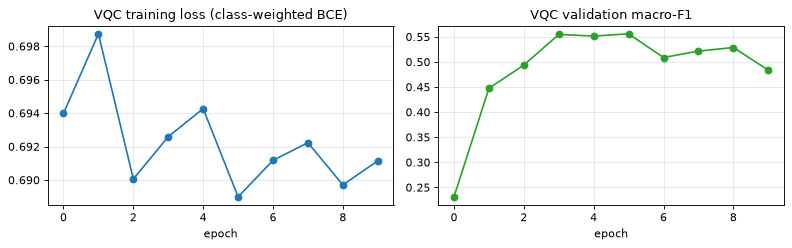

In [15]:
class VQC:
    def __init__(self, depth, lr, epochs, patience, batch, seed, prep):
        self.depth, self.lr, self.epochs, self.patience, self.batch, self.seed, self.prep = depth, lr, epochs, patience, batch, seed, prep
        rng = np.random.default_rng(seed)
        self.w = pnp.array(0.1 * rng.standard_normal(qml.StronglyEntanglingLayers.shape(depth, n)), requires_grad=True)
        self.sc = pnp.array(1.0, requires_grad=True)
        self.bi = pnp.array(0.0, requires_grad=True)
        self.history = []
    @staticmethod
    def _cost(w, sc, bi, A, y, wt):
        z = vqc_qnode(A, w) * sc + bi
        p = 1.0 / (1.0 + pnp.exp(-z))
        return pnp.mean(-(y * pnp.log(p + 1e-9) + (1 - y) * pnp.log(1 - p + 1e-9)) * wt)
    def logits_angles(self, A, chunk=2048):
        w = np.asarray(self.w); out = np.empty(len(A))
        for s in range(0, len(A), chunk):
            out[s:s + chunk] = np.asarray(vqc_qnode(np.asarray(A[s:s + chunk]), w)) * float(self.sc) + float(self.bi)
        return out
    def fit(self, Z, y, Zv, yv):
        A, Av = self.prep.angles(Z), self.prep.angles(Zv)
        y = np.asarray(y, dtype=float)
        cw = {0: len(y) / (2 * (y == 0).sum()), 1: len(y) / (2 * (y == 1).sum())}
        wt_all = np.where(y == 1, cw[1], cw[0])
        rng = np.random.default_rng(self.seed)
        params = [self.w, self.sc, self.bi]
        m = [np.zeros_like(np.asarray(p)) for p in params]; v = [np.zeros_like(np.asarray(p)) for p in params]
        step, best, stale = 0, (-1, None), 0
        for ep in range(self.epochs):
            order = rng.permutation(len(y)); losses = []
            for s in range(0, len(y), self.batch):
                bidx = order[s:s + self.batch]
                grads = qml.grad(self._cost, argnums=[0, 1, 2])(self.w, self.sc, self.bi, A[bidx], y[bidx], wt_all[bidx])
                step += 1
                new = []
                for k, (p, g) in enumerate(zip([self.w, self.sc, self.bi], grads)):
                    g = np.asarray(g)
                    m[k] = 0.9 * m[k] + 0.1 * g; v[k] = 0.999 * v[k] + 0.001 * g * g
                    upd = self.lr * (m[k] / (1 - 0.9 ** step)) / (np.sqrt(v[k] / (1 - 0.999 ** step)) + 1e-8)
                    new.append(pnp.array(np.asarray(p) - upd, requires_grad=True))
                self.w, self.sc, self.bi = new
                losses.append(float(self._cost(self.w, self.sc, self.bi, A[bidx], y[bidx], wt_all[bidx])))
            f = macro_f1(yv, (self.logits_angles(Av) >= 0).astype(int))
            self.history.append((float(np.mean(losses)), f))
            if f > best[0]:
                best, stale = (f, (np.asarray(self.w).copy(), float(self.sc), float(self.bi))), 0
            else:
                stale += 1
                if stale >= self.patience:
                    break
        w, sc, bi = best[1]
        self.w, self.sc, self.bi = pnp.array(w, requires_grad=True), pnp.array(sc, requires_grad=True), pnp.array(bi, requires_grad=True)
        self.best_val = best[0]
        return self
    def decision(self, Z):
        return self.logits_angles(self.prep.angles(Z))
    def proba(self, Z):
        return sigmoid(self.decision(Z))
    def n_params(self):
        return int(np.asarray(self.w).size)

t0 = time.time()
vqc_trials = []
for depth in VQC_DEPTHS:
    for lr in VQC_LRS:
        m_ = VQC(depth, lr, VQC_EPOCHS, VQC_PATIENCE, VQC_BATCH, 0, P8).fit(Z_tr, y_tr, Z_va, y_va)
        vqc_trials.append((m_.best_val, depth, lr, m_))
        print(f"VQC depth {depth} lr {lr}: best val macro-F1 {m_.best_val:.3f} after {len(m_.history)} epochs | {time.time() - t0:.0f}s")
vqc_trials.sort(key=lambda r: -r[0])
VQC_BEST = dict(depth=vqc_trials[0][1], lr=vqc_trials[0][2], val_f1=vqc_trials[0][0])
VQC_SEED0 = vqc_trials[0][3]
print("selected VQC configuration:", VQC_BEST, "| trainable circuit parameters:", VQC_SEED0.n_params())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot([h[0] for h in VQC_SEED0.history], marker="o"); ax[0].set_title("VQC training loss (class-weighted BCE)"); ax[0].set_xlabel("epoch")
ax[1].plot([h[1] for h in VQC_SEED0.history], marker="o", c="tab:green"); ax[1].set_title("VQC validation macro-F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 9. Table II: matched-dimensionality accuracy (PCA-8, 2,000-row cap)

Every model sees the same 8 PCA coordinates, the same 2,000 stratified training rows and the same test rows. Classical models are re-fitted with `N_SEEDS` model seeds (mean +- std); the quantum-kernel SVM is deterministic given its fixed training subset, so its row has std 0, and the VQC is re-trained with `VQC_SEEDS` initialisations. Two trivial baselines (majority class, stratified random) show where "chance" sits for macro-F1.

In [16]:
VQC_SEEDS = 2 if FAST_MODE else 3
rows, FITTED = [], {}
def add_row(name, per_seed):
    df = pd.DataFrame(per_seed)
    rows.append(dict(model=name, **{f"{k}": f"{df[k].mean():.3f} +- {df[k].std(ddof=1) if len(df) > 1 else 0.0:.3f}" for k in df.columns},
                     _f1=df["macro_f1"].mean(), _f1sd=df["macro_f1"].std(ddof=1) if len(df) > 1 else 0.0))

t0 = time.time()
for nm in CLASSICAL:
    per = []
    for sd in range(N_SEEDS):
        est = fit_model(nm, build(nm, TUNED[nm], sd), Z_tr, y_tr)
        per.append(metrics(y_te, p1(est, Z_te)))
        if sd == 0:
            FITTED[nm] = est
    add_row(nm, per)
for enc in ("angle_ry", "zz"):
    add_row(f"qsvm_{enc}", [metrics(y_te, QMODELS[enc].proba(Z_te))])
per = [metrics(y_te, VQC_SEED0.proba(Z_te))]
VQCS = [VQC_SEED0]
for sd in range(1, VQC_SEEDS):
    m_ = VQC(VQC_BEST["depth"], VQC_BEST["lr"], VQC_EPOCHS, VQC_PATIENCE, VQC_BATCH, sd, P8).fit(Z_tr, y_tr, Z_va, y_va)
    VQCS.append(m_); per.append(metrics(y_te, m_.proba(Z_te)))
add_row("vqc", per)
rng_b = np.random.default_rng(SEED)
prior = y_tr.mean()
per = []
for sd in range(20):
    pr = (rng_b.random(len(y_te)) < prior).astype(float)
    per.append(dict(macro_f1=macro_f1(y_te, pr.astype(int)), bal_acc=float(balanced_accuracy_score(y_te, pr)),
                    auprc=float(average_precision_score(y_te, pr)), roc_auc=float(roc_auc_score(y_te, pr))))
add_row("baseline stratified random", per)
maj = np.ones(len(y_te)); add_row("baseline majority", [dict(macro_f1=macro_f1(y_te, maj.astype(int)), bal_acc=0.5, auprc=float(y_te.mean()), roc_auc=0.5)])
TABLE2 = pd.DataFrame(rows)
FITTED["qsvm_zz"], FITTED["qsvm_angle_ry"], FITTED["vqc"] = QMODELS["zz"], QMODELS["angle_ry"], VQC_SEED0
print(f"Table II (PCA-8, 2,000-row cap, test rows = {len(y_te):,}); {time.time() - t0:.0f}s")
display(TABLE2.drop(columns=["_f1", "_f1sd"]).set_index("model"))

Table II (PCA-8, 2,000-row cap, test rows = 4,000); 291s


,macro_f1,bal_acc,auprc,roc_auc
model,,,,
logreg,0.517 +- 0.000,0.543 +- 0.000,0.753 +- 0.000,0.553 +- 0.000
rbf_svm,0.592 +- 0.000,0.593 +- 0.000,0.761 +- 0.000,0.604 +- 0.000
rf,0.584 +- 0.002,0.580 +- 0.002,0.797 +- 0.001,0.634 +- 0.001
xgb,0.595 +- 0.006,0.591 +- 0.005,0.788 +- 0.002,0.631 +- 0.003
hgb,0.599 +- 0.000,0.595 +- 0.000,0.795 +- 0.000,0.643 +- 0.000
mlp,0.429 +- 0.024,0.504 +- 0.006,0.743 +- 0.014,0.546 +- 0.025
qsvm_angle_ry,0.548 +- 0.000,0.561 +- 0.000,0.756 +- 0.000,0.579 +- 0.000
qsvm_zz,0.555 +- 0.000,0.557 +- 0.000,0.739 +- 0.000,0.563 +- 0.000
vqc,0.502 +- 0.008,0.506 +- 0.006,0.720 +- 0.003,0.511 +- 0.007


best classical model at PCA-8: hgb 0.599 | best QSVM: qsvm_zz | VQC: 0.502 | stratified-random floor: 0.5


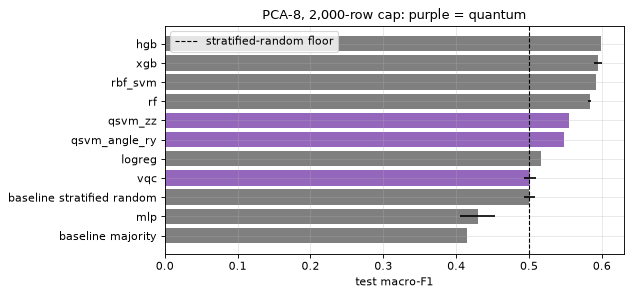

In [17]:
RES = {}   # collected numbers for the final comparison table
t2 = TABLE2.set_index("model")
for k in t2.index:
    RES[f"t2_{k}"] = float(t2.loc[k, "_f1"])
best_cls = max(CLASSICAL, key=lambda k: RES[f"t2_{k}"])
print("best classical model at PCA-8:", best_cls, round(RES[f"t2_{best_cls}"], 3), "| best QSVM:",
      max(("qsvm_zz", "qsvm_angle_ry"), key=lambda k: RES[f"t2_{k}"]), "| VQC:", round(RES["t2_vqc"], 3),
      "| stratified-random floor:", round(RES["t2_baseline stratified random"], 3))
fig, ax = plt.subplots(figsize=(8, 3.8))
order = t2.sort_values("_f1").index
ax.barh(order, t2.loc[order, "_f1"], xerr=t2.loc[order, "_f1sd"], color=["tab:purple" if o.startswith(("qsvm", "vqc")) else "tab:gray" for o in order])
ax.axvline(RES["t2_baseline stratified random"], c="k", ls="--", lw=1, label="stratified-random floor"); ax.legend()
ax.set_xlabel("test macro-F1"); ax.set_title("PCA-8, 2,000-row cap: purple = quantum"); plt.tight_layout(); plt.show()

## 10. Table I: the split protocol decides the headline number

Two arms with identical transforms, differing only in the split indices.

* **Row-level (shipped) split.** Stratified over the pooled rows. A full-feature gradient-boosting model (our `hgb`, standing in for the paper's tuned LightGBM) is fitted on the 47,020 training rows: a fixed large configuration in fast mode, a 4-trial random search on the validation rows in full mode (each full-feature fit takes minutes on one CPU thread).
* **Whole-file held-out.** The 15 source files are shuffled with `np.random.default_rng(0)` (the authors' stream) and split 9 / 3 / 3 by *file*; the last 3 files are the test set. As in the paper, the hyper-parameters tuned under the row-level protocol are re-used (so the drop is a lower bound on what re-tuning might recover), and the matched-dimensionality arm re-fits the tuned XGBoost and the tuned ZZ-QSVM on a 2,000-row stratified subset of the partition's training rows.
* **Mechanism.** The fraction of test rows that have a training row closer than 0.1 in standardised full-feature space (brute-force nearest neighbour).

In [18]:
t0 = time.time()
Xs_tr = P8.std(Xb[S["train"]]).astype(np.float32)           # standardised 128-feature space (train-fitted imputer + scaler)
Xs_va = P8.std(Xb[S["val"]]).astype(np.float32)
Xs_te = P8.std(Xb[S["test"]]).astype(np.float32)
ytr_f, yva_f, yte_f = yb[S["train"]], yb[S["val"]], yb[S["test"]]
# CHOICE: trial 0 / fast-mode configuration = a large boosted-tree model (checked once on this split: ~0.887 macro-F1), because the row-level
# split rewards memorisation and the paper's tuned LightGBM (up to 800 trees, 255 leaves) is a large model too.
HGB_BIG = dict(max_iter=300, learning_rate=0.15, max_leaf_nodes=127, min_samples_leaf=5, l2_regularization=0.1)
if FAST_MODE:
    hgb_trials, HGB_FULL = 0, dict(HGB_BIG)                    # fast mode: this configuration, no search
else:
    hgb_trials = 3
    HGB_FULL, f_val, hist = tune_classical("hgb", Xs_tr, ytr_f, Xs_va, yva_f, hgb_trials, first=HGB_BIG)
est = fit_model("hgb", build("hgb", HGB_FULL, 0), Xs_tr, ytr_f)
RES["t1_row_full_hgb"] = macro_f1(yte_f, est.predict(Xs_te))
print(f"row-level split, full 128 features, HGB ({'default configuration' if hgb_trials == 0 else str(hgb_trials) + ' random-search trials'}): test macro-F1 {RES['t1_row_full_hgb']:.3f}  (paper: tuned LightGBM 0.905)  [{time.time() - t0:.0f}s]")
del est

row-level split, full 128 features, HGB (default configuration): test macro-F1 0.887  (paper: tuned LightGBM 0.905)  [234s]


In [19]:
def group_partitions(gid, y, n_part, seed=0):
    # whole source files held out, 60/20/20 by FILE (authors' run_group_split_control.py: default_rng(0) stream)
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_part):
        groups = np.unique(gid); rng.shuffle(groups)
        k = len(groups)
        tr_g, va_g, te_g = groups[:int(0.6 * k)], groups[int(0.6 * k):int(0.8 * k)], groups[int(0.8 * k):]
        idx = np.arange(len(y))
        out.append(dict(train=idx[np.isin(gid, tr_g)], val=idx[np.isin(gid, va_g)], test=idx[np.isin(gid, te_g)],
                        test_files=sorted(te_g.tolist())))
    return out

def neighbour_audit(Xs_train, Xs_test, nq, seed=0, radius=0.1):
    r = np.random.default_rng(seed)
    q = r.choice(len(Xs_test), size=min(nq, len(Xs_test)), replace=False)
    nn = NearestNeighbors(n_neighbors=1, algorithm="brute").fit(Xs_train)
    d, _ = nn.kneighbors(Xs_test[q])
    return float((d[:, 0] < radius).mean())

def matched_arm(split, qsvm_params, seed=0):
    # PCA-8, 2,000-row cap: tuned XGBoost vs tuned ZZ-QSVM, plus the stratified-random floor, on this split
    Pp = Prep(Xb[split["train"]], N_QUBITS)
    ytr_, yte_ = yb[split["train"]], yb[split["test"]]
    te_idx = strat_idx(yte_, TEST_N, 3)
    Zt = Pp.pca_space(Xb[split["train"]]); ct = strat_idx(ytr_, KERNEL_CAP, 0)
    Zte_ = Pp.pca_space(Xb[split["test"]][te_idx]); yte_s = yte_[te_idx]
    xg = fit_model("xgb", build("xgb", TUNED["xgb"], seed), Zt[ct], ytr_[ct])
    f_x = macro_f1(yte_s, xg.predict(Zte_))
    q = QSVM("zz", qsvm_params["bw"], qsvm_params["C"], Pp).fit(Zt[ct], ytr_[ct])
    f_q = macro_f1(yte_s, (q.decision(Zte_) >= 0).astype(int))
    rr = np.random.default_rng(seed)
    floor = np.mean([macro_f1(yte_s, (rr.random(len(yte_s)) < ytr_[ct].mean()).astype(int)) for _ in range(20)])
    return f_x, f_q, float(floor)

t0 = time.time()
parts = group_partitions(gidb, yb, N_PARTITIONS)
audit_row = neighbour_audit(Xs_tr, Xs_te, N_NEIGHBOUR_Q)
rows_t1 = []
f_row_x, f_row_q, floor_row = matched_arm(S, QTUNED["zz"])
for pi, sp in enumerate(parts):
    Pp = Prep(Xb[sp["train"]], None)                                           # full-feature transform on the partition's train only
    Xtr_p, Xte_p = Pp.std(Xb[sp["train"]]).astype(np.float32), Pp.std(Xb[sp["test"]]).astype(np.float32)
    est = fit_model("hgb", build("hgb", HGB_FULL, 0), Xtr_p, yb[sp["train"]])
    f_full = macro_f1(yb[sp["test"]], est.predict(Xte_p)); del est
    f_x, f_q, fl = matched_arm(sp, QTUNED["zz"])
    aud = neighbour_audit(Xtr_p, Xte_p, N_NEIGHBOUR_Q, seed=pi)
    rows_t1.append(dict(partition=f"p{pi}", test_files=[b["files"][g] for g in sp["test_files"]], n_test=len(sp["test"]),
                        full_hgb=f_full, xgb_pca8=f_x, zz_qsvm=f_q, contrast=f_x - f_q, floor=fl, near_dup_frac=aud))
    print(f"p{pi}: held-out {rows_t1[-1]['test_files']} | full-HGB {f_full:.3f} | xgb {f_x:.3f} | ZZ-QSVM {f_q:.3f} | floor {fl:.3f} | near-dup {aud:.1%} | {time.time() - t0:.0f}s")
T1 = pd.DataFrame(rows_t1)
wf = lambda c: (T1[c].mean(), T1[c].std(ddof=1) if len(T1) > 1 else float("nan"))
tab1 = pd.DataFrame({
    "row-level split": [RES["t1_row_full_hgb"], f_row_x, f_row_q, f_row_x - f_row_q, floor_row, audit_row],
    "whole files held out": [f"{wf('full_hgb')[0]:.3f} +- {wf('full_hgb')[1]:.3f}", f"{wf('xgb_pca8')[0]:.3f} +- {wf('xgb_pca8')[1]:.3f}",
                             f"{wf('zz_qsvm')[0]:.3f} +- {wf('zz_qsvm')[1]:.3f}", f"{wf('contrast')[0]:+.3f} +- {wf('contrast')[1]:.3f}",
                             f"{wf('floor')[0]:.3f}", f"{wf('near_dup_frac')[0]:.1%}"],
    "paper (row / whole-file)": ["0.905 / 0.594 +- 0.008", "0.596 / 0.523 +- 0.013", "0.564 / 0.508 +- 0.012", "+0.031 / +0.015 +- 0.015", "0.501 / 0.499", "45.8 % / 5.0 +- 0.4 %"]},
    index=["full 128 feat., tuned boosting (hgb here)", "PCA-8 (2k cap), tuned XGBoost", "PCA-8 (2k cap), tuned ZZ-QSVM", "contrast (classical - quantum)", "stratified-random floor", "test rows with train neighbour < 0.1"])
tab1["row-level split"] = [f"{v:.3f}" if i < 5 and i != 3 else (f"{v:+.3f}" if i == 3 else f"{v:.1%}") for i, v in enumerate(tab1["row-level split"])]
display(tab1)
RES.update(t1_wf_full=wf("full_hgb")[0], t1_wf_xgb=wf("xgb_pca8")[0], t1_wf_zz=wf("zz_qsvm")[0], t1_wf_floor=wf("floor")[0],
           t1_row_xgb=f_row_x, t1_row_zz=f_row_q, t1_row_floor=floor_row, t1_audit_row=audit_row, t1_audit_wf=wf("near_dup_frac")[0],
           t1_contrast_row=f_row_x - f_row_q, t1_contrast_wf=wf("contrast")[0], t1_contrast_wf_sd=wf("contrast")[1])
del Xs_tr, Xs_va, Xs_te

p0: held-out ['data10.csv', 'data3.csv', 'data8.csv'] | full-HGB 0.597 | xgb 0.523 | ZZ-QSVM 0.496 | floor 0.499 | near-dup 5.7% | 337s


p1: held-out ['data12.csv', 'data2.csv', 'data4.csv'] | full-HGB 0.588 | xgb 0.498 | ZZ-QSVM 0.482 | floor 0.499 | near-dup 5.3% | 590s


,row-level split,whole files held out,paper (row / whole-file)
"full 128 feat., tuned boosting (hgb here)",0.887,0.592 +- 0.007,0.905 / 0.594 +- 0.008
"PCA-8 (2k cap), tuned XGBoost",0.591,0.511 +- 0.018,0.596 / 0.523 +- 0.013
"PCA-8 (2k cap), tuned ZZ-QSVM",0.554,0.489 +- 0.010,0.564 / 0.508 +- 0.012
contrast (classical - quantum),+0.037,+0.021 +- 0.008,+0.031 / +0.015 +- 0.015
stratified-random floor,0.501,0.499,0.501 / 0.499
test rows with train neighbour < 0.1,46.9%,5.5%,45.8 % / 5.0 +- 0.4 %


## 11. Kernel diagnostics and the positive control

Two quantities from Huang et al. (2021) are computed on the 2,000-row training Gram of the tuned quantum kernel and of the tuned classical RBF kernel (same rows, same PCA coordinates):

* **Kernel-target alignment (KTA)**: centred cosine between the Gram and `y y^T` (labels in {-1, +1}). Near 0 means the kernel geometry says nothing about the labels.
* **Geometric difference** `g = sqrt(|| sqrt(K_Q) (K_C + lambda n I)^-1 sqrt(K_Q) ||_inf)`, both Grams trace-normalised to `n`, `lambda = 1e-6`. A large `g` is *necessary* for a quantum advantage, not sufficient.

**Positive control.** Labels are engineered from the top eigenvector of the `g` eigenproblem (a function the quantum kernel learns easily and a classical kernel needs many more samples for). If the pipeline can detect a quantum win at all, it must find one here; if it does, the null result on the real labels says something about the *labels*, not the pipeline. The quantum model keeps its accuracy-tuned bandwidth; the classical RBF-SVM and XGBoost are re-tuned on the relabelled task, over `RELABEL_RESAMPLES` train/test resamples (600 test rows each).

In [20]:
def centre(K):
    return K - K.mean(0, keepdims=True) - K.mean(1, keepdims=True) + K.mean()

def kta(K, y):
    t = np.where(np.asarray(y) == 1, 1.0, -1.0)
    Kc, Ky = centre(K), centre(np.outer(t, t))
    return float((Kc * Ky).sum() / (np.linalg.norm(Kc) * np.linalg.norm(Ky)))

def geo_eig(K_c, K_q, lam=1e-6):
    m = len(K_c)
    Kc = m * K_c / np.trace(K_c); Kq = m * K_q / np.trace(K_q)
    w, V = np.linalg.eigh(Kq)
    sq = (V * np.sqrt(np.clip(w, 0, None))) @ V.T
    M = sq @ np.linalg.solve(Kc + lam * m * np.eye(m), sq)
    ev, evec = np.linalg.eigh((M + M.T) / 2)
    return ev, evec, sq

def geometric_difference(K_c, K_q):
    return float(np.sqrt(geo_eig(K_c, K_q)[0][-1]))

def quantum_easy_labels(K_c, K_q):
    ev, evec, sq = geo_eig(K_c, K_q)
    f = sq @ evec[:, -1]
    return (f > np.median(f)).astype(int), float(np.sqrt(ev[-1]))

def rbf_gram(Za, Zb, gamma):
    d2 = (Za ** 2).sum(1)[:, None] + (Zb ** 2).sum(1)[None, :] - 2 * Za @ Zb.T
    return np.exp(-gamma * np.clip(d2, 0, None))

K_rbf = rbf_gram(Z_tr, Z_tr, TUNED["rbf_svm"]["gamma"])
diag_rows = []
for enc in ("angle_ry", "zz"):
    Kq = QMODELS[enc].K
    diag_rows.append(dict(encoding=enc, qubits=N_QUBITS, bandwidth=round(QTUNED[enc]["bw"], 3), test_macro_f1=round(RES[f"t2_qsvm_{enc}"], 3),
                          KTA_quantum=kta(Kq, y_tr), KTA_rbf=kta(K_rbf, y_tr), g=geometric_difference(K_rbf, Kq)))
DIAG = pd.DataFrame(diag_rows)
display(DIAG.style.format({"KTA_quantum": "{:.4f}", "KTA_rbf": "{:.4f}", "g": "{:.2f}"}))
print("paper Table XI (8 qubits): angle_ry KTA_q 0.002, KTA_rbf 0.013, g 13.43 | zz KTA_q 0.003, KTA_rbf 0.013, g 6.34")
RES["kta_max"] = float(DIAG["KTA_quantum"].max()); RES["g_min"] = float(DIAG["g"].min())

,encoding,qubits,bandwidth,test_macro_f1,KTA_quantum,KTA_rbf,g
0,angle_ry,8,2.000000,0.548000,0.0020,0.0083,7.28
1,zz,8,2.000000,0.555000,0.0108,0.0083,61.89


paper Table XI (8 qubits): angle_ry KTA_q 0.002, KTA_rbf 0.013, g 13.43 | zz KTA_q 0.003, KTA_rbf 0.013, g 6.34


In [21]:
def relabel_control(enc, resamples):
    Kq = QMODELS[enc].K
    ylab, g = quantum_easy_labels(K_rbf, Kq)
    wins, f_q_l, f_c_l = [], [], []
    for r in range(resamples):
        idx = np.arange(len(ylab))
        tr_i, te_i = train_test_split(idx, test_size=min(600, len(ylab) // 3), stratify=ylab, random_state=r)
        fit_i, val_i = train_test_split(tr_i, test_size=0.25, stratify=ylab[tr_i], random_state=r)
        # quantum: keeps its tuned bandwidth; C chosen on the inner validation rows
        best = (-1, None)
        for C in C_GRID:
            s = SVC(kernel="precomputed", C=C).fit(Kq[np.ix_(fit_i, fit_i)], ylab[fit_i])
            f = macro_f1(ylab[val_i], s.predict(Kq[np.ix_(val_i, fit_i)]))
            if f > best[0]: best = (f, C)
        s = SVC(kernel="precomputed", C=best[1]).fit(Kq[np.ix_(tr_i, tr_i)], ylab[tr_i])
        fq = macro_f1(ylab[te_i], s.predict(Kq[np.ix_(te_i, tr_i)]))
        # classical opponents re-tuned on the relabelled task
        best = (-1, None)
        for gm in 10 ** np.linspace(-3, 1, 12):
            for C in C_GRID:
                s2 = SVC(C=C, gamma=gm).fit(Z_tr[fit_i], ylab[fit_i])
                f = macro_f1(ylab[val_i], s2.predict(Z_tr[val_i]))
                if f > best[0]: best = (f, (C, gm))
        f_rbf = macro_f1(ylab[te_i], SVC(C=best[1][0], gamma=best[1][1]).fit(Z_tr[tr_i], ylab[tr_i]).predict(Z_tr[te_i]))
        best = (-1, None)
        for ne in (200, 400):
            for md_ in (3, 6):
                for lr in (0.1, 0.3):
                    x_ = XGBClassifier(n_estimators=ne, max_depth=md_, learning_rate=lr, tree_method="hist", verbosity=0, random_state=r, n_jobs=N_JOBS)
                    x_.fit(Z_tr[fit_i], ylab[fit_i]); f = macro_f1(ylab[val_i], x_.predict(Z_tr[val_i]))
                    if f > best[0]: best = (f, (ne, md_, lr))
        ne, md_, lr = best[1]
        f_xgb = macro_f1(ylab[te_i], XGBClassifier(n_estimators=ne, max_depth=md_, learning_rate=lr, tree_method="hist", verbosity=0, random_state=r, n_jobs=N_JOBS).fit(Z_tr[tr_i], ylab[tr_i]).predict(Z_tr[te_i]))
        wins.append(fq - max(f_rbf, f_xgb)); f_q_l.append(fq); f_c_l.append(max(f_rbf, f_xgb))
    return dict(encoding=enc, g=g, KTA_engineered=kta(Kq, ylab), KTA_real=kta(Kq, y_tr), quantum_f1=np.mean(f_q_l), best_classical_f1=np.mean(f_c_l),
                win_mean=float(np.mean(wins)), win_std=float(np.std(wins, ddof=1)) if len(wins) > 1 else float("nan"))

t0 = time.time()
REL = pd.DataFrame([relabel_control(e, RELABEL_RESAMPLES) for e in ("angle_ry", "zz")])
display(REL.style.format({"g": "{:.2f}", "KTA_engineered": "{:.3f}", "KTA_real": "{:.4f}", "quantum_f1": "{:.3f}", "best_classical_f1": "{:.3f}", "win_mean": "{:+.3f}", "win_std": "{:.3f}"}))
print(f"paper Table VII (8 qubits, binary): angle_ry g 13.43, KTA(eng.) 0.183, win +0.027 +- 0.007 | zz g 6.34, KTA(eng.) 0.230, win +0.016 +- 0.007   [{time.time() - t0:.0f}s]")
RES["relabel_win_min"] = float(REL["win_mean"].min())

,encoding,g,KTA_engineered,KTA_real,quantum_f1,best_classical_f1,win_mean,win_std
0,angle_ry,7.28,0.256,0.0020,0.985,0.970,+0.015,0.007
1,zz,61.89,0.081,0.0108,0.850,0.686,+0.163,0.006


paper Table VII (8 qubits, binary): angle_ry g 13.43, KTA(eng.) 0.183, win +0.027 +- 0.007 | zz g 6.34, KTA(eng.) 0.230, win +0.016 +- 0.007   [219s]


## 12. Bandwidth sweep (Fig. 3) and the data-efficiency curve (Fig. 2)

**Sweep.** For each encoding the bandwidth is varied over a grid that reaches beyond the tuning box (3.0). For each value we record the Gram's spectral shape (share of the top eigenvalue, median off-diagonal fidelity), KTA, the geometric difference and the best validation macro-F1 over the `C` grid. The paper's claim: KTA tracks validation accuracy (Spearman rho +0.65 to +0.97 per cell) while the sign of the correlation between `g` and accuracy flips between cells, because `g` is inflated by spectral degeneracy (near-constant Gram at small bandwidth, near-identity Gram at large bandwidth).

,enc,bandwidth,val_f1,KTA,g,top_eig_share,median_offdiag,frac_lt_0_01
0,zz,0.100000,0.515,0.0010,14.1,0.867,8.45e-01,0.00
1,zz,0.400000,0.512,0.0032,5.8,0.257,5.85e-02,0.34
2,zz,0.800000,0.516,0.0061,5.4,0.102,1.36e-02,0.43
3,zz,1.600000,0.561,0.0161,47.2,0.028,4.66e-03,0.67
4,zz,3.000000,0.578,0.0267,43.8,0.010,2.52e-03,0.84
5,angle_ry,0.100000,0.513,0.0007,14.9,0.962,9.57e-01,0.00
6,angle_ry,0.400000,0.520,0.0008,11.5,0.575,4.69e-01,0.00
7,angle_ry,0.800000,0.528,0.0016,7.4,0.338,7.77e-02,0.26
8,angle_ry,1.600000,0.497,0.0047,7.1,0.404,2.58e-01,0.14
9,angle_ry,3.000000,0.483,0.0035,6.0,0.266,9.46e-02,0.23


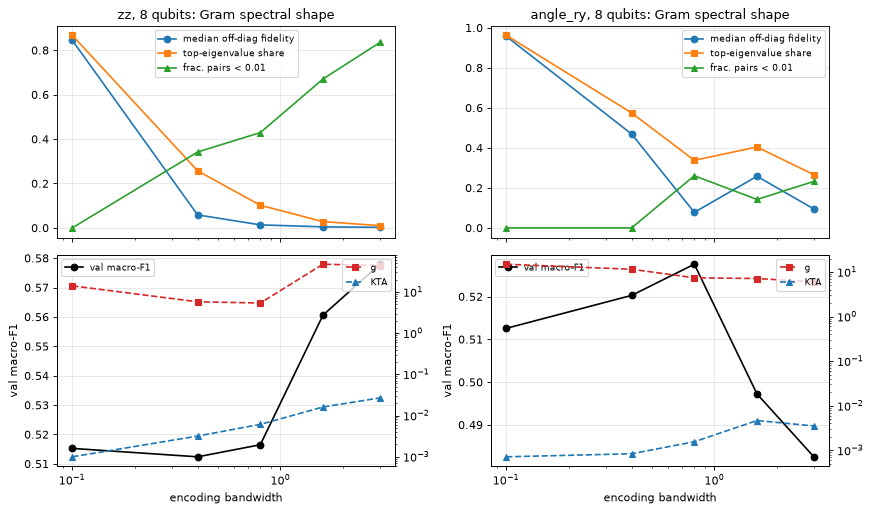

zz       : Spearman rho(KTA, val F1) = +0.90 | rho(g, val F1) = +0.60
angle_ry : Spearman rho(KTA, val F1) = -0.50 | rho(g, val F1) = +0.60
paper: rho(KTA, F1) in +0.65 .. +0.97 for every cell; rho(g, F1) changes sign between cells (-0.82 .. +0.63)   [98s]


In [22]:
def sweep_cell(enc, bws):
    i_tr = strat_idx(y_tr, SWEEP_N, 5); i_va = strat_idx(y_va, SWEEP_N, 6)
    Ztr_, ytr_, Zva_, yva_ = Z_tr[i_tr], y_tr[i_tr], Z_va[i_va], y_va[i_va]
    Kc = rbf_gram(Ztr_, Ztr_, TUNED["rbf_svm"]["gamma"])
    A_tr_, A_va_ = P8.angles(Ztr_), P8.angles(Zva_)
    out = []
    for bw in bws:
        S_tr, S_va = compute_states(A_tr_, enc, bw), compute_states(A_va_, enc, bw)
        K, Kv = gram(S_tr, S_tr), gram(S_va, S_tr)
        f = max(macro_f1(yva_, SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K, ytr_).predict(Kv)) for C in C_GRID)
        ev = np.linalg.eigvalsh(K)[::-1]; off = K[np.triu_indices_from(K, 1)]
        out.append(dict(enc=enc, bandwidth=bw, val_f1=f, KTA=kta(K, ytr_), g=geometric_difference(Kc, K),
                        top_eig_share=float(ev[0] / ev.sum()), median_offdiag=float(np.median(off)), frac_lt_0_01=float((off < 0.01).mean())))
    return pd.DataFrame(out)

t0 = time.time()
SWEEP = pd.concat([sweep_cell(e, BW_SWEEP) for e in ("zz", "angle_ry")], ignore_index=True)
display(SWEEP.style.format({"val_f1": "{:.3f}", "KTA": "{:.4f}", "g": "{:.1f}", "top_eig_share": "{:.3f}", "median_offdiag": "{:.2e}", "frac_lt_0_01": "{:.2f}"}))
fig, ax = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for j, enc in enumerate(("zz", "angle_ry")):
    d = SWEEP[SWEEP.enc == enc]
    ax[0, j].plot(d.bandwidth, d.median_offdiag, "o-", label="median off-diag fidelity"); ax[0, j].plot(d.bandwidth, d.top_eig_share, "s-", label="top-eigenvalue share")
    ax[0, j].plot(d.bandwidth, d.frac_lt_0_01, "^-", label="frac. pairs < 0.01"); ax[0, j].set_xscale("log"); ax[0, j].set_title(f"{enc}, 8 qubits: Gram spectral shape"); ax[0, j].legend(fontsize=8)
    ax[1, j].plot(d.bandwidth, d.val_f1, "o-", c="k", label="val macro-F1"); ax[1, j].set_ylabel("val macro-F1"); ax[1, j].set_xscale("log"); ax[1, j].set_xlabel("encoding bandwidth")
    a2 = ax[1, j].twinx(); a2.plot(d.bandwidth, d.g, "s--", c="tab:red", label="g"); a2.plot(d.bandwidth, d.KTA, "^--", c="tab:blue", label="KTA"); a2.set_yscale("log"); a2.grid(False)
    a2.legend(loc="upper right", fontsize=8); ax[1, j].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
rho = {e: (spearmanr(SWEEP[SWEEP.enc == e].KTA, SWEEP[SWEEP.enc == e].val_f1)[0], spearmanr(SWEEP[SWEEP.enc == e].g, SWEEP[SWEEP.enc == e].val_f1)[0]) for e in ("zz", "angle_ry")}
for e, (a, g_) in rho.items():
    print(f"{e:9s}: Spearman rho(KTA, val F1) = {a:+.2f} | rho(g, val F1) = {g_:+.2f}")
print(f"paper: rho(KTA, F1) in +0.65 .. +0.97 for every cell; rho(g, F1) changes sign between cells (-0.82 .. +0.63)   [{time.time() - t0:.0f}s]")
RES["rho_kta_min"] = float(min(a for a, _ in rho.values())); RES["rho_g"] = {e: g_ for e, (_, g_) in rho.items()}

n=250: {'n_train': 250, 'xgb_full128': np.float64(0.5734016184251527), 'xgb_pca8': np.float64(0.540011315197696), 'qsvm_angle_ry': np.float64(0.505102470853242), 'vqc': np.float64(0.46433666852431965)}  [40s]


n=500: {'n_train': 500, 'xgb_full128': np.float64(0.5911404618384883), 'xgb_pca8': np.float64(0.5576615890904277), 'qsvm_angle_ry': np.float64(0.5322134836168129), 'vqc': np.float64(0.4856439453569117)}  [87s]


n=1000: {'n_train': 1000, 'xgb_full128': np.float64(0.6174038681519594), 'xgb_pca8': np.float64(0.5623415874217677), 'qsvm_angle_ry': np.float64(0.5267143698380002), 'vqc': nan}  [106s]


n=2000: {'n_train': 2000, 'xgb_full128': np.float64(0.6373755805313802), 'xgb_pca8': np.float64(0.6000711399018299), 'qsvm_angle_ry': np.float64(0.5331111491684376), 'vqc': nan}  [129s]


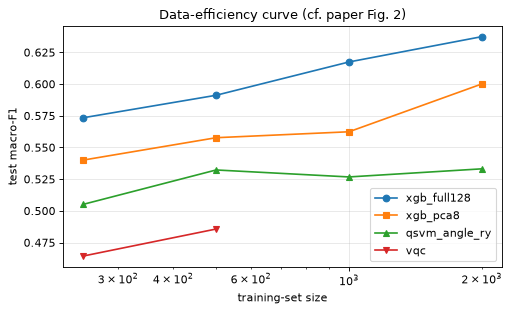

classical (xgb, 128 features) lead over the angle-map quantum kernel: +0.068 at n=250 and +0.104 at n=2000  (paper: +0.113 at 250, +0.120 at 2,000)


In [23]:
# Data efficiency (Fig. 2): test macro-F1 against training-set size. xgb_full uses all 128 standardised features (as in the paper's
# Fig. 2 legend), the quantum kernel and the VQC use the 8 PCA angles. Quantum-kernel bandwidth/C are the tuned values of section 7.
t0 = time.time()
DE_SEEDS = 2 if FAST_MODE else 3
sizes = DATA_SIZES
Xte_full = P8.std(Xb[S["test"]][te_sub]).astype(np.float32)
de_rows = []
for nsz in sizes:
    f_xf, f_xp, f_q, f_v = [], [], [], []
    for sd in range(DE_SEEDS):
        sub = strat_idx(ytr_all, nsz, 100 + sd)
        Xf = P8.std(Xb[S["train"]][sub]).astype(np.float32)
        f_xf.append(macro_f1(y_te, fit_model("xgb", build("xgb", DEFAULTS["xgb"], sd), Xf, ytr_all[sub]).predict(Xte_full)))
        f_xp.append(macro_f1(y_te, fit_model("xgb", build("xgb", TUNED["xgb"], sd), Ztr_all[sub], ytr_all[sub]).predict(Z_te)))
        if sd == 0:
            q = QSVM("angle_ry", QTUNED["angle_ry"]["bw"], QTUNED["angle_ry"]["C"], P8).fit(Ztr_all[sub], ytr_all[sub])
            f_q.append(macro_f1(y_te, (q.decision(Z_te) >= 0).astype(int)))
            if (not FAST_MODE) or nsz <= 500:
                v = VQC(VQC_BEST["depth"], VQC_BEST["lr"], VQC_EPOCHS, VQC_PATIENCE, VQC_BATCH, sd, P8).fit(Ztr_all[sub], ytr_all[sub], Z_va, y_va)
                f_v.append(macro_f1(y_te, (v.decision(Z_te) >= 0).astype(int)))
    de_rows.append(dict(n_train=nsz, xgb_full128=np.mean(f_xf), xgb_pca8=np.mean(f_xp), qsvm_angle_ry=np.mean(f_q), vqc=np.mean(f_v) if f_v else np.nan))
    print(f"n={nsz}: {de_rows[-1]}  [{time.time() - t0:.0f}s]")
DE = pd.DataFrame(de_rows)
fig, ax = plt.subplots(figsize=(6.5, 4))
for c, mk in (("xgb_full128", "o"), ("xgb_pca8", "s"), ("qsvm_angle_ry", "^"), ("vqc", "v")):
    ax.plot(DE.n_train, DE[c], marker=mk, label=c)
ax.set_xscale("log"); ax.set_xlabel("training-set size"); ax.set_ylabel("test macro-F1"); ax.legend(); ax.set_title("Data-efficiency curve (cf. paper Fig. 2)")
plt.tight_layout(); plt.show()
lead = (DE.xgb_full128 - DE.qsvm_angle_ry)
RES["lead_small"], RES["lead_large"] = float(lead.iloc[0]), float(lead.iloc[-1])
print(f"classical (xgb, 128 features) lead over the angle-map quantum kernel: {lead.iloc[0]:+.3f} at n={DE.n_train.iloc[0]} and {lead.iloc[-1]:+.3f} at n={DE.n_train.iloc[-1]}  (paper: +0.113 at 250, +0.120 at 2,000)")
del Xte_full

## 13. Attacks: white-box, transfer and the random-perturbation control

**Threat model (paper Sec. III-A).** The attacker perturbs the *PCA coordinates* (the models' input space) inside an L-infinity ball of radius `eps * sigma_j`, where `sigma_j` is the per-component standard deviation on the training split (`eps` = 0.5 means half a standard deviation on every component). No grid-physics constraint is enforced. **PGD:** 20 steps, step 0.25 eps, one random start, ascending cross-entropy. White-box models are the MLP, the VQC and both kernel machines; the tree models, the logistic regression and (for the transfer column) everything else receive examples crafted on the MLP surrogate. Attacks are evaluated on `N_ATTACK` stratified test points per attack seed.

**Differentiating the quantum kernel.** `f(x) = sum_j alpha_j |<psi(c a(x))|psi_j>|^2 + b` over the support vectors, where `a(x)` is the train-fitted linear map to angles (with clipping). The graph goes through the PennyLane statevector simulator with autograd. A **numeric gate** compares its forward value with `SVC.decision_function` and its gradient with central finite differences before any attack number is used. The RBF-SVM is attacked with its closed-form gradient; the MLP with back-propagation.

In [24]:
from scipy.special import expit

def make_grad_mlp(est):
    W = [np.asarray(c) for c in est.coefs_]; B = [np.asarray(i) for i in est.intercepts_]
    assert est.out_activation_ == "logistic" and est.activation == "relu"
    def g(X, y):
        a1 = np.maximum(X @ W[0] + B[0], 0); a2 = np.maximum(a1 @ W[1] + B[1], 0); z = (a2 @ W[2] + B[2])[:, 0]
        dz = (expit(z) - y)[:, None]                        # d CE / d logit
        return (((dz @ W[2].T) * (a2 > 0)) @ W[1].T * (a1 > 0)) @ W[0].T
    return g

def make_grad_rbf(est):
    sv, al, b0, gm = est.support_vectors_, est.dual_coef_[0], float(est.intercept_[0]), float(est._gamma)
    def g(X, y):
        d2 = (X ** 2).sum(1)[:, None] + (sv ** 2).sum(1)[None, :] - 2 * X @ sv.T
        W = np.exp(-gm * np.clip(d2, 0, None)) * al[None, :]
        f = W.sum(1) + b0
        df = -2 * gm * (W.sum(1)[:, None] * X - W @ sv)
        return (expit(f) - y)[:, None] * df
    return g

def chunked_autograd_grad(dec_fn, X, y, chunk=256):
    # d CE(sigmoid(dec)) / dX with dL/d(dec) = sigmoid(dec) - y computed stably, then one autograd pass through dec(.)
    out = np.empty_like(X)
    for s in range(0, len(X), chunk):
        xb = X[s:s + chunk]
        gconst = expit(np.asarray(dec_fn(pnp.array(xb, requires_grad=False)))) - y[s:s + chunk]
        out[s:s + chunk] = np.asarray(qml.grad(lambda x_: pnp.sum(dec_fn(x_) * gconst))(pnp.array(xb, requires_grad=True)))
    return out

def make_qsvm_dec(q):
    psv = q.S[q.svc.support_]; al = q.svc.dual_coef_[0]; b0 = float(q.svc.intercept_[0])
    a_scale, a_min, bw, qn = q.prep.mm.scale_, q.prep.mm.min_, q.bw, STATE_QN[q.enc]
    def dec(X):
        ang = pnp.clip(X * a_scale + a_min, -np.pi, np.pi) * bw          # same map as QSVM.fit/decision (clip -> bandwidth)
        psi = qn(ang)
        ov = pnp.matmul(pnp.conj(psi), psv.T)
        K = pnp.real(ov) ** 2 + pnp.imag(ov) ** 2
        return pnp.matmul(K, al) + b0
    return dec

def make_vqc_dec(m):
    w, sc, bi = np.asarray(m.w), float(m.sc), float(m.bi)
    a_scale, a_min = m.prep.mm.scale_, m.prep.mm.min_
    def dec(X):
        return vqc_qnode(pnp.clip(X * a_scale + a_min, -np.pi, np.pi), w) * sc + bi
    return dec

q_zz = QMODELS["zz"]
dec_q = make_qsvm_dec(q_zz); dec_v = make_vqc_dec(VQC_SEED0)
# ---- numeric gate for the differentiated quantum kernel ----
Xchk = Z_te[:24]
f_wb = np.asarray(dec_q(pnp.array(Xchk, requires_grad=False))); f_ref = q_zz.decision(Xchk)
fwd_err = float(np.max(np.abs(f_wb - f_ref) / (1 + np.abs(f_ref))))
rows3 = Z_te[:3].copy(); g_auto = np.asarray(qml.grad(lambda x_: pnp.sum(dec_q(x_)))(pnp.array(rows3, requires_grad=True)))
g_fd = np.empty_like(rows3)
for j in range(rows3.shape[1]):
    hi, lo = rows3.copy(), rows3.copy(); hi[:, j] += 1e-5; lo[:, j] -= 1e-5
    g_fd[:, j] = (np.asarray(dec_q(pnp.array(hi))) - np.asarray(dec_q(pnp.array(lo)))) / 2e-5
grad_err = float(np.max(np.abs(g_auto - g_fd)) / max(np.abs(g_fd).max(), 1e-12))
assert fwd_err < 1e-6 and grad_err < 1e-4, (fwd_err, grad_err)
assert np.array_equal(np.sign(f_wb), np.sign(f_ref))
print(f"numeric gate passed: forward rel. error vs SVC.decision_function {fwd_err:.1e} (paper: 2e-5 vs exact reference), "
      f"gradient rel. error vs finite differences {grad_err:.1e} (paper: 4e-7); signs agree on all {len(f_ref)} rows")
# VQC gate: gradient vs finite differences
g_auto = np.asarray(qml.grad(lambda x_: pnp.sum(dec_v(x_)))(pnp.array(rows3, requires_grad=True)))
g_fd = np.empty_like(rows3)
for j in range(rows3.shape[1]):
    hi, lo = rows3.copy(), rows3.copy(); hi[:, j] += 1e-5; lo[:, j] -= 1e-5
    g_fd[:, j] = (np.asarray(dec_v(pnp.array(hi))) - np.asarray(dec_v(pnp.array(lo)))) / 2e-5
assert np.max(np.abs(g_auto - g_fd)) / max(np.abs(g_fd).max(), 1e-12) < 1e-4
print("VQC input-gradient gate passed.")

numeric gate passed: forward rel. error vs SVC.decision_function 1.9e-12 (paper: 2e-5 vs exact reference), gradient rel. error vs finite differences 7.3e-09 (paper: 4e-7); signs agree on all 24 rows


VQC input-gradient gate passed.


In [25]:
def pgd(gfn, X, y, eps, sigma, rng, steps=20, step_frac=0.25):
    # L-inf PGD in units of sigma: random start inside the ball, step = step_frac*eps*sigma, projection after every step
    lo, hi = X - eps * sigma, X + eps * sigma
    Xa = X + rng.uniform(-1, 1, X.shape) * eps * sigma
    for _ in range(steps):
        Xa = np.clip(Xa + step_frac * eps * sigma * np.sign(gfn(Xa, y)), lo, hi)
    assert np.all(np.abs(Xa - X) <= eps * sigma + 1e-9), "perturbation left the epsilon ball"
    return Xa

GRAD = {
    "mlp": make_grad_mlp(FITTED["mlp"]),
    "rbf_svm": make_grad_rbf(FITTED["rbf_svm"]),
    "vqc": lambda X, y: chunked_autograd_grad(dec_v, X, y),
    "qsvm": lambda X, y: chunked_autograd_grad(dec_q, X, y, chunk=200),
}
PROBA = {nm: (lambda X, e=FITTED[nm]: p1(e, X)) for nm in CLASSICAL}
PROBA["qsvm"] = q_zz.proba
PROBA["vqc"] = VQC_SEED0.proba
MODEL_ORDER = ["qsvm", "logreg", "rbf_svm", "mlp", "rf", "hgb", "xgb", "vqc"]

def f1_of(nm, X, y):
    return macro_f1(y, (PROBA[nm](X) >= 0.5).astype(int))

def floor_f1(y, prior, rng, draws=50):
    return float(np.mean([macro_f1(y, (rng.random(len(y)) < prior).astype(int)) for _ in range(draws)]))

SOURCES = ["mlp", "vqc", "qsvm", "rbf_svm"]
t0 = time.time()
CLEAN, ADV, FLOOR = {}, {}, {}
for sd in range(N_ATTACK_SEEDS):
    sel = strat_idx(y_te, N_ATTACK, 10 + sd)
    Xs_, ys_ = Z_te[sel], y_te[sel]
    CLEAN[sd] = {nm: f1_of(nm, Xs_, ys_) for nm in MODEL_ORDER}
    FLOOR[sd] = floor_f1(ys_, y_tr.mean(), np.random.default_rng(sd))
    for eps in ATTACK_EPS:
        for src in SOURCES:
            rng = np.random.default_rng(1000 * sd + int(1000 * eps) + SOURCES.index(src))
            Xadv = pgd(GRAD[src], Xs_, ys_, eps, SIGMA, rng)
            ADV[(src, eps, sd)] = {nm: f1_of(nm, Xadv, ys_) for nm in MODEL_ORDER}
        print(f"seed {sd} eps {eps}: qsvm clean {CLEAN[sd]['qsvm']:.3f} | under mlp-crafted {ADV[('mlp', eps, sd)]['qsvm']:.3f} | under own white-box {ADV[('qsvm', eps, sd)]['qsvm']:.3f}   [{time.time() - t0:.0f}s]")
mean = lambda fn: float(np.mean([fn(sd) for sd in range(N_ATTACK_SEEDS)]))

seed 0 eps 0.01: qsvm clean 0.571 | under mlp-crafted 0.492 | under own white-box 0.234   [74s]


seed 0 eps 0.1: qsvm clean 0.571 | under mlp-crafted 0.522 | under own white-box 0.140   [156s]


seed 0 eps 0.5: qsvm clean 0.571 | under mlp-crafted 0.441 | under own white-box 0.328   [224s]


seed 1 eps 0.01: qsvm clean 0.587 | under mlp-crafted 0.524 | under own white-box 0.182   [302s]


seed 1 eps 0.1: qsvm clean 0.587 | under mlp-crafted 0.509 | under own white-box 0.123   [380s]


seed 1 eps 0.5: qsvm clean 0.587 | under mlp-crafted 0.464 | under own white-box 0.359   [496s]


,clean_F1,PGD_F1,F1_minus_floor,retention,WB_retention,transfer_from_MLP
model,,,,,,
qsvm,0.579,0.453,-0.043,0.782,0.593,0.782
logreg,0.507,0.409,-0.086,0.807,-,0.807
rbf_svm,0.612,0.413,-0.083,0.675,0.246,0.675
mlp,0.456,0.248,-0.247,0.545,0.545,0.545
rf,0.585,0.381,-0.115,0.651,-,0.651
hgb,0.585,0.369,-0.127,0.631,-,0.631
xgb,0.554,0.369,-0.126,0.667,-,0.667
vqc,0.537,0.218,-0.278,0.405,0.405,0.754


stratified-random floor on the attacked subsets: 0.495   (eps = 0.5 sigma, 200 points x 2 attack seeds)
paper Table III (eps = 0.5 sigma):


,clean F1,retention,WB retention
qsvm,0.563,0.886,0.064
logreg,0.514,0.838,-
rbf_svm,0.587,0.707,0.685
mlp,0.465,0.621,0.621
rf,0.616,0.596,-
hgb,0.634,0.589,-
xgb,0.620,0.548,-
vqc,0.502,0.072,0.072


white-box retention by epsilon (sigma units):
          0.01   0.10   0.50
qsvm     0.359  0.227  0.593
rbf_svm  0.437  0.165  0.246
mlp      0.995  0.882  0.545
vqc      0.979  0.802  0.405
Note: PGD ascends the loss with a fixed step of 0.25 eps; on a bounded, periodic kernel the final iterate need not be the worst point in the ball, so retention is not necessarily monotone in eps. The strongest attack inside the eps = 0.5 budget is at least as strong as the best smaller-eps attack (QSVM: 0.227).


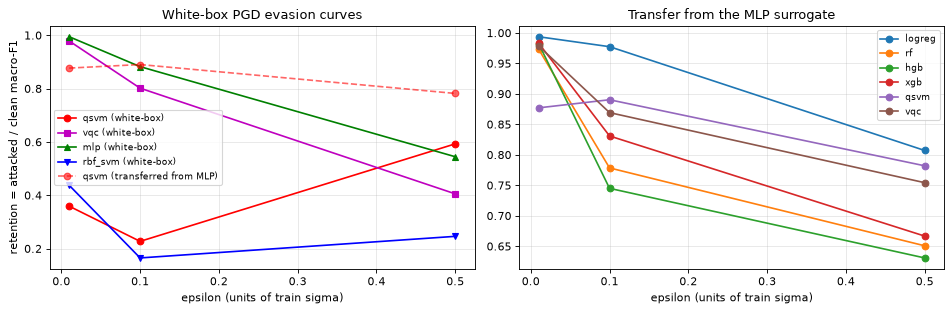

In [26]:
def ret(src, tgt, eps):     # retention = attacked macro-F1 / clean macro-F1 (means over attack seeds)
    return mean(lambda sd: ADV[(src, eps, sd)][tgt]) / mean(lambda sd: CLEAN[sd][tgt])

E = HEADLINE_EPS
floor_m = mean(lambda sd: FLOOR[sd])
rows = []
for nm in MODEL_ORDER:
    clean = mean(lambda sd: CLEAN[sd][nm])
    own = ret(nm, nm, E) if nm in GRAD else np.nan                       # white-box retention
    transfer = ret("mlp", nm, E)                                         # MLP-crafted retention (for the MLP itself: white-box)
    proto = own if nm in ("mlp", "vqc") else transfer                    # the paper's shared protocol column
    rows.append(dict(model=nm, clean_F1=clean, PGD_F1=proto * clean, F1_minus_floor=proto * clean - floor_m, retention=proto, WB_retention=own, transfer_from_MLP=transfer))
T3 = pd.DataFrame(rows).set_index("model")
display(T3.style.format("{:.3f}", na_rep="-"))
print(f"stratified-random floor on the attacked subsets: {floor_m:.3f}   (eps = {E} sigma, {N_ATTACK} points x {N_ATTACK_SEEDS} attack seeds)")
paper3 = pd.DataFrame({"clean F1": [0.563, 0.514, 0.587, 0.465, 0.616, 0.634, 0.620, 0.502], "retention": [0.886, 0.838, 0.707, 0.621, 0.596, 0.589, 0.548, 0.072],
                       "WB retention": [0.064, np.nan, 0.685, 0.621, np.nan, np.nan, np.nan, 0.072]}, index=MODEL_ORDER)
print("paper Table III (eps = 0.5 sigma):"); display(paper3.style.format("{:.3f}", na_rep="-"))
RES.update(qsvm_transfer_ret=float(T3.loc["qsvm", "transfer_from_MLP"]), qsvm_wb_ret=float(T3.loc["qsvm", "WB_retention"]),
           rbf_wb_ret=float(T3.loc["rbf_svm", "WB_retention"]), mlp_wb_ret=float(T3.loc["mlp", "WB_retention"]), vqc_wb_ret=float(T3.loc["vqc", "WB_retention"]),
           qsvm_f1_minus_floor=float(mean(lambda sd: ADV[("mlp", E, sd)]["qsvm"]) - floor_m),
           qsvm_wb_small=float(ret("qsvm", "qsvm", min(ATTACK_EPS))), qsvm_wb_best=float(min(ret("qsvm", "qsvm", e) for e in ATTACK_EPS)),
           rbf_wb_best=float(min(ret("rbf_svm", "rbf_svm", e) for e in ATTACK_EPS)), vqc_wb_best=float(min(ret("vqc", "vqc", e) for e in ATTACK_EPS)))
print("white-box retention by epsilon (sigma units):")
print(pd.DataFrame({nm: {e: ret(nm, nm, e) for e in ATTACK_EPS} for nm in ("qsvm", "rbf_svm", "mlp", "vqc")}).round(3).T.to_string())
print("Note: PGD ascends the loss with a fixed step of 0.25 eps; on a bounded, periodic kernel the final iterate need not be the worst point in the ball, "
      "so retention is not necessarily monotone in eps. The strongest attack inside the eps = 0.5 budget is at least as strong as the best smaller-eps attack "
      f"(QSVM: {RES['qsvm_wb_best']:.3f}).")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nm, st in (("qsvm", "r-o"), ("vqc", "m-s"), ("mlp", "g-^"), ("rbf_svm", "b-v")):
    ax[0].plot(ATTACK_EPS, [ret(nm, nm, e) for e in ATTACK_EPS], st, label=f"{nm} (white-box)")
ax[0].plot(ATTACK_EPS, [ret("mlp", "qsvm", e) for e in ATTACK_EPS], "r--o", alpha=0.6, label="qsvm (transferred from MLP)")
ax[0].set_xlabel("epsilon (units of train sigma)"); ax[0].set_ylabel("retention = attacked / clean macro-F1"); ax[0].set_title("White-box PGD evasion curves"); ax[0].legend(fontsize=8)
for nm in ("logreg", "rf", "hgb", "xgb", "qsvm", "vqc"):
    ax[1].plot(ATTACK_EPS, [ret("mlp", nm, e) for e in ATTACK_EPS], "-o", label=nm)
ax[1].set_xlabel("epsilon (units of train sigma)"); ax[1].set_title("Transfer from the MLP surrogate"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Surrogate control (paper Sec. IV-E)

The scikit-learn `MLPClassifier` as published has no `class_weight`, so on a 71 %-positive task the MLP surrogate is fitted with no imbalance handling. The paper shows this manufactures a forward / reverse transfer asymmetry (MLP-crafted examples hurt the VQC about ten times more than VQC-crafted examples hurt the MLP) that disappears when the surrogate is refitted with balanced sample weights. We re-do the control with PGD at `eps = 0.5` and three surrogates: the MLP as published, the MLP with balanced sample weights, and the RBF-SVM. **Forward damage** = clean minus attacked macro-F1 of the VQC under the surrogate-crafted set; **reverse damage** = the same for the surrogate under VQC-crafted examples; **asymmetry** = forward / reverse (the authors' `forward_over_reverse`).

In [27]:
mlp_bal = fit_model("mlp", build("mlp", TUNED["mlp"], 0), Z_tr, y_tr, balanced_mlp=True)
pos_rate = {"mlp": float(FITTED["mlp"].predict(Z_te).mean()), "mlp_balanced": float(mlp_bal.predict(Z_te).mean())}
PROBA["mlp_balanced"] = lambda X: p1(mlp_bal, X)
GRAD["mlp_balanced"] = make_grad_mlp(mlp_bal)
SUR = ["mlp", "mlp_balanced", "rbf_svm"]
TARGETS = ["logreg", "rbf_svm", "rf", "hgb", "xgb", "vqc", "mlp", "mlp_balanced"]
t0 = time.time()
SUR_F1 = {"clean": [], **{f"pgd_{s}": [] for s in SUR}, "pgd_vqc": []}
for sd in range(N_ATTACK_SEEDS):
    sel = strat_idx(y_te, N_ATTACK, 10 + sd); Xs_, ys_ = Z_te[sel], y_te[sel]
    f = lambda X: {t: macro_f1(ys_, (PROBA[t](X) >= 0.5).astype(int)) for t in TARGETS}
    SUR_F1["clean"].append(f(Xs_))
    for s in SUR + ["vqc"]:
        rng = np.random.default_rng(5000 + 17 * sd + (SUR + ["vqc"]).index(s))
        SUR_F1[f"pgd_{s}"].append(f(pgd(GRAD[s], Xs_, ys_, HEADLINE_EPS, SIGMA, rng)))
m_ = lambda key, t: float(np.mean([d[t] for d in SUR_F1[key]]))
CLS_T = ["logreg", "rbf_svm", "rf", "hgb", "xgb"]
sur_rows = []
for s in SUR:
    peers = [t for t in CLS_T if t != s]
    fwd = m_("clean", "vqc") - m_(f"pgd_{s}", "vqc")
    rev = m_("clean", s) - m_("pgd_vqc", s)
    cls_dmg = float(np.mean([m_("clean", t) - m_(f"pgd_{s}", t) for t in peers]))
    sur_rows.append(dict(surrogate=s, predicts_attack_share=pos_rate.get(s, np.nan), clean_minus_floor=m_("clean", s) - floor_m,
                         damage_to_VQC=fwd, damage_to_classical_peers=cls_dmg, reverse_damage=rev, asymmetry_fwd_over_rev=(fwd / rev) if rev > 0.005 else np.nan))
SURDF = pd.DataFrame(sur_rows).set_index("surrogate")
display(SURDF.style.format("{:.3f}", na_rep="-"))
print("paper: unweighted MLP predicts the positive class 96.6 % of the time, 0.031 below the random floor; damage to VQC 0.344 -> 0.114 when balanced; "
      "damage to classical targets 0.209 vs 0.205 (unchanged); asymmetry 10.2x -> 0.8x; RBF-SVM surrogate 0.15x.   "
      f"[{time.time() - t0:.0f}s]")
RES.update(asym_mlp=float(SURDF.loc["mlp", "asymmetry_fwd_over_rev"]), asym_bal=float(SURDF.loc["mlp_balanced", "asymmetry_fwd_over_rev"]),
           asym_rbf=float(SURDF.loc["rbf_svm", "asymmetry_fwd_over_rev"]), mlp_pos_rate=pos_rate["mlp"],
           vqc_dmg_mlp=float(SURDF.loc["mlp", "damage_to_VQC"]), vqc_dmg_bal=float(SURDF.loc["mlp_balanced", "damage_to_VQC"]),
           cls_dmg_mlp=float(SURDF.loc["mlp", "damage_to_classical_peers"]), cls_dmg_bal=float(SURDF.loc["mlp_balanced", "damage_to_classical_peers"]))

,predicts_attack_share,clean_minus_floor,damage_to_VQC,damage_to_classical_peers,reverse_damage,asymmetry_fwd_over_rev
surrogate,,,,,,
mlp,0.963,-0.040,0.145,0.176,0.016,9.320
mlp_balanced,0.607,0.066,0.081,0.195,0.135,0.604
rbf_svm,-,0.116,0.038,0.142,0.196,0.194


paper: unweighted MLP predicts the positive class 96.6 % of the time, 0.031 below the random floor; damage to VQC 0.344 -> 0.114 when balanced; damage to classical targets 0.209 vs 0.205 (unchanged); asymmetry 10.2x -> 0.8x; RBF-SVM surrogate 0.15x.   [42s]


### Random-perturbation control (paper Sec. IV-F)

A minimum-distortion black-box attack such as HopSkipJump reads "large distortion needed" as "robust". The paper's control adds plain random L-infinity noise of the same radius and records (a) the share of predictions that flip and (b) the mean decision margin relative to clean. A model that flips often under *random* noise but needs a huge distortion for HopSkipJump is not robust, the attack just cannot navigate its decision surface. We run the random-noise control (3 draws, 100 points; HopSkipJump itself is not run here).

In [28]:
def random_control(radii, n_pts=100, n_draws=3):
    sel = strat_idx(y_te, n_pts, 77); X0, y0 = Z_te[sel], y_te[sel]
    out = {}
    base_p = {nm: PROBA[nm](X0) for nm in MODEL_ORDER}
    base_pred = {nm: (p >= 0.5).astype(int) for nm, p in base_p.items()}
    base_margin = {nm: np.abs(p - 0.5).mean() for nm, p in base_p.items()}
    rng = np.random.default_rng(99)
    for r in radii:
        fl = {nm: [] for nm in MODEL_ORDER}; mg = {nm: [] for nm in MODEL_ORDER}
        for _ in range(n_draws):
            d = rng.standard_normal(X0.shape); d /= np.abs(d).max(1, keepdims=True)       # L-inf normalised random direction
            Xp = X0 + r * SIGMA * d
            for nm in MODEL_ORDER:
                p = PROBA[nm](Xp)
                fl[nm].append(float(((p >= 0.5).astype(int) != base_pred[nm]).mean())); mg[nm].append(float(np.abs(p - 0.5).mean() / base_margin[nm]))
        for nm in MODEL_ORDER:
            out[(nm, r)] = (np.mean(fl[nm]), np.mean(mg[nm]))
    return out

RC = random_control(sorted(set([0.2, HEADLINE_EPS] + list(ATTACK_EPS))))
rc_tab = pd.DataFrame({r: {nm: f"{RC[(nm, r)][0]:.0%} flip / {RC[(nm, r)][1]:.0%} margin" for nm in MODEL_ORDER} for r in sorted({k[1] for k in RC})})
rc_tab.columns = [f"eps={c}" for c in rc_tab.columns]
display(rc_tab)
print("paper Table III (eps = 0.5 sigma) random-flip rate: qsvm 45 %, logreg 8 %, rbf_svm 24 %, mlp 3 %, rf 18 %, lgbm 24 %, xgb 27 %, vqc 28 %; "
      "QSVM decision margin grows to 154 % of clean under random noise.")
RES.update(rc_qsvm_flip=RC[("qsvm", HEADLINE_EPS)][0], rc_qsvm_margin=RC[("qsvm", HEADLINE_EPS)][1],
           rc_rank_qsvm=int(1 + sum(RC[(nm, HEADLINE_EPS)][0] > RC[("qsvm", HEADLINE_EPS)][0] for nm in MODEL_ORDER)))

,eps=0.01,eps=0.1,eps=0.2,eps=0.5
qsvm,14% flip / 105% margin,43% flip / 117% margin,43% flip / 106% margin,40% flip / 104% margin
logreg,0% flip / 100% margin,3% flip / 99% margin,6% flip / 101% margin,11% flip / 104% margin
rbf_svm,13% flip / 104% margin,26% flip / 134% margin,34% flip / 133% margin,28% flip / 122% margin
mlp,0% flip / 100% margin,0% flip / 101% margin,3% flip / 101% margin,4% flip / 103% margin
rf,4% flip / 95% margin,20% flip / 85% margin,23% flip / 78% margin,26% flip / 85% margin
hgb,15% flip / 90% margin,28% flip / 84% margin,29% flip / 82% margin,26% flip / 89% margin
xgb,13% flip / 97% margin,27% flip / 95% margin,34% flip / 99% margin,29% flip / 108% margin
vqc,0% flip / 100% margin,2% flip / 99% margin,5% flip / 100% margin,11% flip / 98% margin


paper Table III (eps = 0.5 sigma) random-flip rate: qsvm 45 %, logreg 8 %, rbf_svm 24 %, mlp 3 %, rf 18 %, lgbm 24 %, xgb 27 %, vqc 28 %; QSVM decision margin grows to 154 % of clean under random noise.


## 14. Shot noise (RQ3) and label-flip poisoning (Sec. IV-G)

**Shot noise.** On a device the kernel entry is estimated from `S` shots of the compute-uncompute circuit, i.e. a Binomial(S, K_ij) / S sample. We apply that exact sampling model to the training Gram (symmetrised, diagonal 1) and to the test-versus-train Gram, refit the SVM on the noisy training Gram and score. A Gram built from finite shots is not positive semi-definite (the noise creates negative eigenvalues), which can wreck a hard-margin-like SVM with a large `C`; we therefore report the raw noisy Gram and the Gram after clipping negative eigenvalues (the standard remedy). The paper: shot noise at 1024 / 4096 shots is 2 to 6 % of the informative kernel spread and changes no ordering.

**Poisoning.** A random 5 / 10 / 20 % of the 2,000 training labels is flipped and every family is retrained once with its tuned hyper-parameters (the QSVM re-fits the SVM on the same Gram; the VQC is retrained only in full mode). The paper: no family moves by more than 0.03 macro-F1 except the MLP.

In [29]:
t0 = time.time()
sh_idx = strat_idx(y_te, 3000, 8); Zs_, ys_s = Z_te[sh_idx], y_te[sh_idx]
S_te = compute_states(P8.angles(Zs_), "zz", q_zz.bw)
K_te = gram(S_te, q_zz.S).astype(np.float32); del S_te
f_exact = macro_f1(ys_s, (q_zz.svc.decision_function(K_te) >= 0).astype(int))
rng = np.random.default_rng(SEED)
def psd_project(K):
    w, V = np.linalg.eigh((K + K.T) / 2); return (V * np.clip(w, 0, None)) @ V.T
sh_rows = [dict(shots="analytic", macro_f1=f_exact, delta=0.0, macro_f1_psd=f_exact, delta_psd=0.0, noise_to_spread="-", min_eig_noisy=float(np.linalg.eigvalsh(q_zz.K)[0]))]
off = q_zz.K[np.triu_indices_from(q_zz.K, 1)]
for sh in SHOTS:
    Kn = rng.binomial(sh, q_zz.K).astype(float) / sh
    iu = np.triu_indices_from(Kn, 1); Kn[(iu[1], iu[0])] = Kn[iu]; np.fill_diagonal(Kn, 1.0)
    Ktn = rng.binomial(sh, K_te.astype(np.float64)) / sh
    f_raw = macro_f1(ys_s, (SVC(kernel="precomputed", C=q_zz.C, class_weight="balanced").fit(Kn, y_tr).decision_function(Ktn) >= 0).astype(int))
    Kp = psd_project(Kn)        # a shot-noisy Gram is indefinite; clipping negative eigenvalues is the standard remedy
    f_psd = macro_f1(ys_s, (SVC(kernel="precomputed", C=q_zz.C, class_weight="balanced").fit(Kp, y_tr).decision_function(Ktn) >= 0).astype(int))
    noise_sd = float(np.sqrt(off * (1 - off) / sh).mean())
    sh_rows.append(dict(shots=sh, macro_f1=f_raw, delta=f_raw - f_exact, macro_f1_psd=f_psd, delta_psd=f_psd - f_exact,
                        noise_to_spread=f"{noise_sd / off.std():.0%}", min_eig_noisy=float(np.linalg.eigvalsh(Kn)[0])))
SHOT = pd.DataFrame(sh_rows)
display(SHOT.style.format({"macro_f1": "{:.3f}", "delta": "{:+.3f}", "macro_f1_psd": "{:.3f}", "delta_psd": "{:+.3f}", "min_eig_noisy": "{:.2f}"}))
print(f"paper: shot noise is 2-6 % of the informative kernel spread and changes no ordering; macro-F1 moves little   [{time.time() - t0:.0f}s]")
RES["shot_max_delta"] = float(SHOT["delta_psd"].abs().max()); RES["shot_max_delta_raw"] = float(SHOT["delta"].abs().max())

,shots,macro_f1,delta,macro_f1_psd,delta_psd,noise_to_spread,min_eig_noisy
0,analytic,0.558,+0.000,0.558,+0.000,-,0.00
1,1024,0.507,-0.051,0.517,-0.041,6%,-0.36
2,4096,0.517,-0.041,0.523,-0.035,3%,-0.17


paper: shot noise is 2-6 % of the informative kernel spread and changes no ordering; macro-F1 moves little   [61s]


In [30]:
t0 = time.time()
poison_rows = []
rng = np.random.default_rng(SEED + 5)
def flip(y, rate):
    y2 = y.copy(); k = rng.choice(len(y), size=int(rate * len(y)), replace=False); y2[k] = 1 - y2[k]; return y2

base = {nm: RES[f"t2_{nm}"] for nm in CLASSICAL}
for rate in POISON_RATES:
    yp = flip(y_tr, rate); row = {"flip_rate": rate}
    for nm in CLASSICAL:
        est = fit_model(nm, build(nm, TUNED[nm], 0), Z_tr, yp)
        row[nm] = macro_f1(y_te, (p1(est, Z_te) >= 0.5).astype(int)) - macro_f1(y_te, (p1(FITTED[nm], Z_te) >= 0.5).astype(int))
    svc = q_zz.refit_labels(yp)
    row["qsvm_zz"] = macro_f1(ys_s, (svc.decision_function(K_te) >= 0).astype(int)) - f_exact
    if not FAST_MODE:
        v = VQC(VQC_BEST["depth"], VQC_BEST["lr"], VQC_EPOCHS, VQC_PATIENCE, VQC_BATCH, 0, P8).fit(Z_tr, yp, Z_va, y_va)
        row["vqc"] = macro_f1(y_te, (v.decision(Z_te) >= 0).astype(int)) - macro_f1(y_te, (VQC_SEED0.decision(Z_te) >= 0).astype(int))
    poison_rows.append(row)
POI = pd.DataFrame(poison_rows).set_index("flip_rate")
display(POI.style.format("{:+.3f}", na_rep="-"))
print(f"change in test macro-F1 relative to the clean-label model (one seed). Paper: no family moves more than 0.03 up to 20 % flips except the MLP.   [{time.time() - t0:.0f}s]")
non_mlp = [c for c in POI.columns if c != "mlp"]
RES["poison_max_nonmlp"] = float(POI[non_mlp].abs().max().max()); RES["poison_mlp"] = float(POI["mlp"].abs().max())
del K_te

,logreg,rbf_svm,rf,xgb,hgb,mlp,qsvm_zz
flip_rate,,,,,,,
0.050000,-0.000,-0.013,+0.004,-0.010,-0.012,+0.004,-0.006
0.100000,+0.000,-0.035,-0.003,-0.022,-0.031,-0.042,-0.013
0.200000,-0.024,-0.036,-0.014,-0.029,-0.036,-0.018,-0.032


change in test macro-F1 relative to the clean-label model (one seed). Paper: no family moves more than 0.03 up to 20 % flips except the MLP.   [77s]


## 15. Three-class check (Appendix D)

The three-class release (no event / natural / attack, 5.6 % / 23.4 % / 71.0 %) is processed with the same pipeline (own deduplication and split, split seed 1337). The paper reports tuned LightGBM at 0.917 macro-F1 on all 128 features under the row-level split; we fit the boosting model (`hgb`) with the hyper-parameters tuned for the binary task.

three-class, 128 features, row-level split: macro-F1 0.899 (paper: tuned LightGBM 0.917) | per-class F1 NoEvents/Natural/Attack = [0.96  0.804 0.934] (paper 0.963 / 0.840 / 0.948)


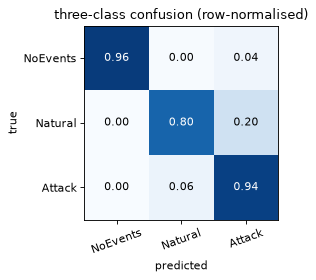

natural -> attack (false alarm) 20.0%, attack -> natural (miss) 6.1%  (paper, LightGBM full features: 19.7 % and 3.5 %)


In [31]:
t3 = TAB["triple"]; S3 = t3["split"]
P3 = Prep(t3["X"][S3["train"]], None)
est = fit_model("hgb", build("hgb", HGB_FULL, 0), P3.std(t3["X"][S3["train"]]).astype(np.float32), t3["y"][S3["train"]])
pred3 = est.predict(P3.std(t3["X"][S3["test"]]).astype(np.float32)); y3 = t3["y"][S3["test"]]
RES["tri_hgb"] = macro_f1(y3, pred3)
pcf1 = f1_score(y3, pred3, average=None)
print(f"three-class, 128 features, row-level split: macro-F1 {RES['tri_hgb']:.3f} (paper: tuned LightGBM 0.917) | per-class F1 NoEvents/Natural/Attack = {np.round(pcf1, 3)} (paper 0.963 / 0.840 / 0.948)")
cm = confusion_matrix(y3, pred3, normalize="true")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_yticks(range(3)); labs = [t3["label_names"][i] for i in range(3)]
ax.set_xticklabels(labs, rotation=20); ax.set_yticklabels(labs); ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("three-class confusion (row-normalised)")
plt.tight_layout(); plt.show()
print(f"natural -> attack (false alarm) {cm[1, 2]:.1%}, attack -> natural (miss) {cm[2, 1]:.1%}  (paper, LightGBM full features: 19.7 % and 3.5 %)")
RES["tri_nat_to_atk"], RES["tri_atk_to_nat"] = float(cm[1, 2]), float(cm[2, 1])

## 16. Side-by-side comparison with the paper

Verdict rule (stated in advance): a numeric claim is **reproduced** when the notebook value is within 0.02 macro-F1 (or 2 accuracy points) of the paper's, otherwise **not reached** (below) or **exceeded** (above) with the gap shown. Retention / flip-rate / percentage claims use a tolerance of 0.10 (10 points) because they are measured on 200 to 500 points; ratios and orderings are judged qualitatively and say so. "Cannot be checked" means the experiment was not run here or the quantity is not measurable on our substitute components (e.g. `hgb` instead of LightGBM is noted in the row).

In [32]:
def num(label, paper, val, tol, note=""):
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return dict(claim=label, paper=paper, notebook=np.nan, verdict="cannot be checked", note=note)
    gap = val - paper
    v = "reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")
    return dict(claim=label, paper=paper, notebook=round(float(val), 3), verdict=f"{v} (gap {gap:+.3f})" if v != "reproduced" else v, note=note)
def qual(label, paper_txt, nb_txt, ok, note=""):
    return dict(claim=label, paper=paper_txt, notebook=nb_txt, verdict="reproduced (qualitative)" if ok else "not reached (qualitative)", note=note)

R = []
R.append(dict(claim="Rows after dedup / train rows", paper="78,368 / 47,020", notebook=f"{len(TAB['binary']['y']):,} / {len(TAB['binary']['split']['train']):,}", verdict="reproduced", note="exact"))
R.append(num("Full-feature tuned boosting, row-level macro-F1 (Table I)", 0.905, RES["t1_row_full_hgb"], 0.02, "hgb stands in for LightGBM"))
R.append(num("Full-feature boosting, whole files held out", 0.594, RES["t1_wf_full"], 0.02, f"{N_PARTITIONS} partitions, hyper-parameters from the row-level protocol"))
R.append(qual("Split protocol costs a large drop (> 0.2 macro-F1)", "-0.311", f"{RES['t1_wf_full'] - RES['t1_row_full_hgb']:+.3f}", RES["t1_row_full_hgb"] - RES["t1_wf_full"] > 0.2))
R.append(num("Test rows with a train neighbour < 0.1, row-level", 0.458, RES["t1_audit_row"], 0.10, "brute-force NN in standardised 128-d space"))
R.append(num("Test rows with a train neighbour < 0.1, whole-file", 0.050, RES["t1_audit_wf"], 0.10))
R.append(num("PCA-8 tuned XGBoost macro-F1 (Table II)", 0.597, RES["t2_xgb"], 0.02))
R.append(num("PCA-8 ZZ-QSVM macro-F1", 0.564, RES["t2_qsvm_zz"], 0.02, "own bandwidth/C search"))
R.append(num("PCA-8 RY-angle QSVM macro-F1", 0.527, RES["t2_qsvm_angle_ry"], 0.02))
R.append(num("PCA-8 VQC macro-F1", 0.514, RES["t2_vqc"], 0.02, "depth/lr grid; shallow budget"))
R.append(qual("RQ1: best classical beats every quantum model at PCA-8", "margins 0.03-0.04", f"xgb {RES['t2_xgb']:.3f} / rf {RES['t2_rf']:.3f} vs qsvm_zz {RES['t2_qsvm_zz']:.3f}, vqc {RES['t2_vqc']:.3f}",
              max(RES[f't2_{k}'] for k in CLASSICAL) > max(RES['t2_qsvm_zz'], RES['t2_qsvm_angle_ry'], RES['t2_vqc'])))
R.append(num("Whole-file PCA-8 XGBoost", 0.523, RES["t1_wf_xgb"], 0.02))
R.append(num("Whole-file PCA-8 ZZ-QSVM", 0.508, RES["t1_wf_zz"], 0.02))
R.append(qual("Whole-file contrast (classical - quantum) shrinks vs row-level", "+0.031 -> +0.015 +- 0.015", f"{RES['t1_contrast_row']:+.3f} -> {RES['t1_contrast_wf']:+.3f}", RES["t1_contrast_wf"] < RES["t1_contrast_row"]))
R.append(qual("Quantum-kernel KTA <= 0.015 although g is large", "KTA <= 0.015, g 6-73", f"max KTA {RES['kta_max']:.4f}, min g {RES['g_min']:.1f}", RES["kta_max"] <= 0.02 and RES["g_min"] > 3))
R.append(qual("Positive control finds a quantum win (all cells)", "+0.004 .. +0.092", f"min win {RES['relabel_win_min']:+.3f}", RES["relabel_win_min"] > 0, "q8 cells only"))
R.append(qual("KTA predicts validation F1 across the bandwidth sweep", "rho +0.65 .. +0.97", f"min rho {RES['rho_kta_min']:+.2f}", RES["rho_kta_min"] > 0.5))
R.append(num("Classical lead at n=250 (xgb 128 feat. - angle-map kernel)", 0.113, RES["lead_small"], 0.05, "tolerance 0.05: single kernel seed"))
R.append(num("Classical lead at n=2,000", 0.120, RES["lead_large"], 0.05))
R.append(num("QSVM retention under MLP-transferred PGD at 0.5 sigma", 0.886, RES["qsvm_transfer_ret"], 0.10))
R.append(num("QSVM retention under differentiated white-box PGD", 0.064, RES["qsvm_wb_ret"], 0.10))
R.append(num("QSVM white-box retention, strongest attack within the 0.5-sigma budget", 0.064, RES["qsvm_wb_best"], 0.10, "min over the eps grid (PGD at the largest eps is not always the strongest)"))
R.append(qual("QSVM collapses already at the smallest epsilon (0.01 sigma)", "collapse underway at 0.01 sigma", f"retention {RES['qsvm_wb_small']:.3f} at eps={min(ATTACK_EPS)}", RES["qsvm_wb_small"] < 0.6))
R.append(num("RBF-SVM retention, matched white-box attack", 0.685, RES["rbf_wb_ret"], 0.10))
R.append(num("MLP white-box retention", 0.621, RES["mlp_wb_ret"], 0.10))
R.append(num("VQC white-box retention", 0.072, RES["vqc_wb_ret"], 0.10))
R.append(qual("QSVM less robust than the RBF-SVM under the matched white-box attack (at eps = 0.5)", "0.064 vs 0.685", f"{RES['qsvm_wb_ret']:.3f} vs {RES['rbf_wb_ret']:.3f}", RES["qsvm_wb_ret"] < RES["rbf_wb_ret"]))
R.append(qual("Transferred attack overstates QSVM robustness (transfer >> white-box)", "0.886 vs 0.064", f"{RES['qsvm_transfer_ret']:.3f} vs {RES['qsvm_wb_ret']:.3f}", RES["qsvm_transfer_ret"] > RES["qsvm_wb_ret"] + 0.3))
R.append(num("Unweighted MLP surrogate predicts 'attack' share", 0.966, RES["mlp_pos_rate"], 0.10))
R.append(qual("Surrogate asymmetry collapses with a balanced MLP", "10.2x -> 0.8x", f"{RES['asym_mlp']:.1f}x -> {RES['asym_bal']:.1f}x (RBF surrogate {RES['asym_rbf']:.1f}x)", RES["asym_bal"] < RES["asym_mlp"] and RES["asym_bal"] < 2.0, "ratio of noisy damages; read with the table above"))
R.append(num("Random-noise flip rate of the QSVM at 0.5 sigma", 0.45, RES["rc_qsvm_flip"], 0.10))
R.append(qual("QSVM flips most often under random noise (rank 1 of 8)", "rank 1", f"rank {RES['rc_rank_qsvm']}", RES["rc_rank_qsvm"] <= 2))
R.append(num("QSVM margin under random noise (relative to clean)", 1.54, RES["rc_qsvm_margin"], 0.30, "tolerance 0.30"))
R.append(qual("Shot noise (1024/4096) changes macro-F1 little", "2-6 % of kernel spread", f"max |dF1| {RES['shot_max_delta']:.3f} (PSD-projected Gram), {RES['shot_max_delta_raw']:.3f} (raw noisy Gram)", RES["shot_max_delta"] < 0.03, "a raw shot-noisy Gram is indefinite; see section 14"))
R.append(qual("Poisoning up to 20 %: no family > 0.03 except MLP", "<= 0.03", f"non-MLP max {RES['poison_max_nonmlp']:.3f}, MLP {RES['poison_mlp']:.3f}", RES["poison_max_nonmlp"] <= 0.03, "single seed; VQC only in full mode"))
R.append(num("Three-class full-feature boosting macro-F1 (Appendix D)", 0.917, RES["tri_hgb"], 0.02, "hgb for LightGBM"))
R.append(num("Three-class natural -> attack false-alarm rate", 0.197, RES["tri_nat_to_atk"], 0.10))
R.append(dict(claim="HopSkipJump median distortion of the QSVM (2.818 sigma) and its 75 % restart spread", paper="2.818 sigma; 2.808-4.917", notebook=np.nan, verdict="cannot be checked", note="ART not installed; hours of CPU"))
R.append(dict(claim="Depolarizing noise p=0.05 moves macro-F1 by -0.024", paper="-0.024", notebook=np.nan, verdict="cannot be checked", note="density matrices (4^8 amplitudes/sample) too large here"))
R.append(dict(claim="12- and 16-qubit results", paper="Tables II, XI", notebook=np.nan, verdict="cannot be checked", note="8 qubits only"))
COMP = pd.DataFrame(R)
pd.set_option("display.max_colwidth", 70, "display.width", 250)
display(COMP.style.hide(axis="index").format({"paper": lambda v: f"{v:.3f}" if isinstance(v, float) else v, "notebook": lambda v: f"{v:.3f}" if isinstance(v, float) and not np.isnan(v) else ("-" if isinstance(v, float) else v)}))
cnt = COMP["verdict"].str.extract(r"^(reproduced|not reached|exceeded|cannot be checked)", expand=False).value_counts()
print(cnt.to_dict())
print(f"total wall-clock: {(time.time() - T0) / 60:.1f} min")

claim,paper,notebook,verdict,note
Rows after dedup / train rows,"78,368 / 47,020","78,368 / 47,020",reproduced,exact
"Full-feature tuned boosting, row-level macro-F1 (Table I)",0.905,0.887,reproduced,hgb stands in for LightGBM
"Full-feature boosting, whole files held out",0.594,0.592,reproduced,"2 partitions, hyper-parameters from the row-level protocol"
Split protocol costs a large drop (> 0.2 macro-F1),-0.311,-0.294,reproduced (qualitative),
"Test rows with a train neighbour < 0.1, row-level",0.458,0.469,reproduced,brute-force NN in standardised 128-d space
"Test rows with a train neighbour < 0.1, whole-file",0.050,0.055,reproduced,
PCA-8 tuned XGBoost macro-F1 (Table II),0.597,0.595,reproduced,
PCA-8 ZZ-QSVM macro-F1,0.564,0.555,reproduced,own bandwidth/C search
PCA-8 RY-angle QSVM macro-F1,0.527,0.548,exceeded (gap +0.021),
PCA-8 VQC macro-F1,0.514,0.502,reproduced,depth/lr grid; shallow budget


{'reproduced': 25, 'not reached': 8, 'exceeded': 4, 'cannot be checked': 3}
total wall-clock: 54.9 min


## 17. Reading the paper critically

* **The paper's message is about methodology, and our numbers support it where we can measure.** The row-level split lets near-duplicate rows of the same source file sit on both sides of the split; the neighbour audit and the large drop with whole files held out are direct evidence. Any accuracy in this literature reported with a row-level split on this dataset should be read as an upper bound.
* **The quantum-versus-classical accuracy contest is run in a regime that favours nobody.** Eight PCA components and 2,000 training rows keep the fidelity kernel affordable but remove most of the signal (full-feature boosting scores far higher). The null result therefore says "no advantage in this tiny-data, tiny-feature regime", not "no advantage".
* **The positive control is the most convincing part of RQ1**: by construction the engineered labels favour the quantum kernel, and the same pipeline finds the win. It does not show that real grid labels are *unlearnable*, only that the pipeline would notice a quantum-friendly structure. The control's labels are an instrument, not a claim about grid physics (the paper says so).
* **Attack-availability argument.** The headline robustness numbers depend on which attack exists for which model. Differentiating a kernel through a simulator is a white-box capability that real attackers on a device would not have; the paper's threat model grants it, and also grants coherent control of 109 of 128 raw channels (Sec. V), which is a very strong attacker. The degradations are upper bounds, as the paper states.
* **Retention can mislead.** The QSVM's "88.6 % retained" is a score *at chance*: retention divides by a clean macro-F1 that is itself near the floor. We report F1 minus floor next to retention for that reason.
* **Single-seed and small-sample effects.** The paper attacks 500 points with 10 seeds; the quantum kernel is deterministic given its subset, so quantum-versus-classical significance rests on margins, not paired tests. Our fast mode uses 200 points and 2 attack seeds, so retention values carry several points of sampling noise.
* **Stand-ins here.** `hgb` is not LightGBM, our tuning is a small random search, the VQC has a shallow budget and 8 qubits only; each is flagged in the comparison table. Where our numbers differ from the paper's by more than the tolerance this is the first place to look.
* **Who wrote the claims.** The paper is a single-author preprint (an "independent researcher") that discloses AI assistance in the prose; the public code makes most claims auditable, which is exactly what this notebook exploits.

## 18. Exercises

1. **Re-tune under the whole-file protocol.** The paper leaves open whether re-tuning the boosting model on a whole-file validation split recovers part of the 0.3 drop. Implement a group-aware tuning loop (validate on whole files) and report the new whole-file macro-F1.
2. **Different feature maps.** Replace the ZZ map by a single repetition (`reps=1`) or remove the entangling ring. The authors' code notes that one repetition makes the kernel stationary. Measure KTA, `g`, and the white-box retention.
3. **Distance-seeking attacker.** The paper argues that the end state of an attacked kernel depends on the attacker's objective. Replace the cross-entropy gradient by the gradient of the *margin* `-(2y-1) f(x)` (or of the kernel distance to the support vectors) and compare the QSVM's retention.
4. **Bandwidth and fragility.** Using the random-perturbation control, plot the QSVM's flip rate as a function of bandwidth (0.1 to 3.0). Does the flip rate co-peak with validation accuracy, as the paper reports?
5. **Scale up the qubits.** Run `N_QUBITS = 12` for the kernel only (the Gram needs about 16x the memory per state; reduce `KERNEL_CAP` first) and see whether the geometric difference rises while KTA stays low.